# Clasificación de flores con transferencia de aprendizaje

## Proyecto 2 de Visión artificial

**Universidad de Medellín**  
Facultad de Ingenierías  
Ingeniería de Sistemas

**Integrantes**

- Jarrison Andrés López Roldán
- Juliana Andrea Betancur Blandón

**Dataset:** `tf_flowers`  
**Fuente:** [TensorFlow Datasets — tf_flowers](https://www.tensorflow.org/datasets/catalog/tf_flowers)

Este notebook construye un clasificador supervisado de fotografías de flores. Compara VGG16 y ResNet50, ambas inicializadas con pesos de ImageNet, mediante transferencia de aprendizaje y fine-tuning. La selección del modelo usa el macro-F1 de validación. El conjunto de prueba permanece reservado hasta después de esa decisión.


## Sección 1. Portada e introducción

### Descripción general

Las fotografías de flores comparten formas, fondos y colores, pero cada especie presenta rasgos visuales propios. El aprendizaje profundo permite extraer esos rasgos de manera automática. Entrenar una red convolucional desde cero, con pocos miles de imágenes, suele ser inestable y costoso. La transferencia de aprendizaje aprovecha filtros ya aprendidos en ImageNet y los adapta al dominio de las flores.

El trabajo compara dos arquitecturas convolucionales, VGG16 y ResNet50. Las dos reciben la misma partición, el mismo tamaño de imagen y una cabeza clasificadora equivalente. La comparación varía la arquitectura, el tamaño de lote y el dropout. Las tasas de aprendizaje permanecen fijas: una para la cabeza y otra para el fine-tuning.

### Problema

Dada una imagen RGB de una flor, asignar una de cinco clases: daisy, dandelion, roses, sunflowers o tulips. Es un problema de **clasificación supervisada multiclase**. La variable objetivo es la etiqueta entera de la clase. No se aborda detección de objetos ni segmentación: cada fotografía se considera un ejemplo de una sola clase.

### Utilidad

Un clasificador de este tipo sirve como apoyo para catalogar colecciones botánicas, organizar inventarios de floristerías, etiquetar contenidos educativos y estudiar, en un caso controlado, cómo se adapta una red preentrenada a un dominio visual distinto del de ImageNet. El beneficio inmediato es reducir la clasificación manual de un conjunto pequeño y bien delimitado. La limitación principal también es clara: el modelo solo conoce estas cinco categorías y no sustituye un criterio taxonómico ni cubre otras plantas, otras condiciones de iluminación o fotografías muy distintas a las del dataset.

### Objetivo general

Desarrollar, comparar y seleccionar un modelo de clasificación de imágenes de `tf_flowers` mediante transferencia de aprendizaje y fine-tuning de VGG16 y ResNet50, con una justificación basada en el macro-F1 de validación y una evaluación final sobre un conjunto de prueba no utilizado durante la selección.

### Objetivos específicos

1. Describir el dataset, su dominio, su variable objetivo y el tipo de problema.
2. Explorar la distribución de clases, las dimensiones reales de las fotografías y ejemplos visuales de las cinco clases.
3. Construir una partición estratificada y reproducible en entrenamiento, validación y prueba.
4. Entrenar la cabeza clasificadora con la base convolucional congelada y, en una segunda fase, ajustar las últimas capas con una tasa de aprendizaje menor.
5. Comparar una malla de arquitecturas e hiperparámetros sin consultar el conjunto de prueba.
6. Evaluar el modelo seleccionado e interpretar aciertos, confusiones, brechas de ajuste y limitaciones.


## Sección 2. Configuración

### Cómo ejecutar el notebook

El entorno de referencia es **Google Colab con GPU**. También puede ejecutarse en local si hay una instalación de TensorFlow compatible, Internet para descargar el dataset y los pesos, y memoria suficiente.

En Colab:

1. Abra `proyecto_2_vision_artificial.ipynb`.
2. Seleccione **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU**.
3. Sitúe el directorio de trabajo en la carpeta del proyecto, para que `resultados/` se escriba junto al notebook. Si hace falta: `%cd /content/ruta_del_proyecto`.
4. Ejecute las celdas en orden, de arriba hacia abajo.
5. La celda de instalación solo descarga paquetes ausentes. `tfds.load` descarga `tf_flowers` (218.21 MiB según el catálogo) en el directorio de datos de TensorFlow Datasets, fuera del repositorio.

En local, desde la raíz del proyecto:

```bash
pip install -r requirements.txt
jupyter notebook proyecto_2_vision_artificial.ipynb
```

### Presupuesto computacional

La celda siguiente concentra la configuración. `MODO_EXPERIMENTO = "completo"` compara 2 arquitecturas, 2 tamaños de lote y 2 valores de dropout (8 entrenamientos). `"reducido"` deja el lote en 32, conserva las dos arquitecturas y los dos dropout (4 entrenamientos) y acorta las épocas. En ambos modos cada entrenamiento incluye cabeza y fine-tuning. EarlyStopping puede detenerse antes del máximo.

Cambiar el modo obliga a ejecutar de nuevo desde la celda de configuración. Las épocas, la paciencia y las tasas también se modifican ahí, sin reescribir el ciclo de experimentos.


In [1]:
from pathlib import Path
import itertools

SEMILLA = 42
TAMANO_IMAGEN = (224, 224)
PROPORCION_ENTRENAMIENTO = 0.70
PROPORCION_VALIDACION = 0.15
PROPORCION_PRUEBA = 0.15
EJEMPLOS_POR_CLASE = 4

MODO_EXPERIMENTO = "completo"  # "completo" o "reducido"

EPOCAS_CABEZA = 6
EPOCAS_AJUSTE = 8
PACIENCIA = 3
TASA_CABEZA = 1e-3
TASA_AJUSTE = 1e-5

ARQUITECTURAS = ["vgg16", "resnet50"]
TAMANOS_LOTE = [16, 32]
DROPOUTS = [0.3, 0.5]

if MODO_EXPERIMENTO == "reducido":
    EPOCAS_CABEZA = 2
    EPOCAS_AJUSTE = 3
    PACIENCIA = 2
    TAMANOS_LOTE = [32]
elif MODO_EXPERIMENTO != "completo":
    raise ValueError("MODO_EXPERIMENTO debe ser 'completo' o 'reducido'.")

suma_proporciones = PROPORCION_ENTRENAMIENTO + PROPORCION_VALIDACION + PROPORCION_PRUEBA
if abs(suma_proporciones - 1.0) > 1e-9:
    raise ValueError("Las proporciones de entrenamiento, validación y prueba deben sumar 1.")

REF_LOTE = TAMANOS_LOTE[0]
REF_DROPOUT = DROPOUTS[0]
COMBINACIONES = list(itertools.product(ARQUITECTURAS, TAMANOS_LOTE, DROPOUTS))

RUTA_RESULTADOS = Path("resultados")
RUTA_FIGURAS = RUTA_RESULTADOS / "figuras"
RUTA_CHECKPOINTS = RUTA_RESULTADOS / "checkpoints"

print(f"Directorio de trabajo: {Path.cwd()}")
print(f"Modo: {MODO_EXPERIMENTO}")
print(f"Combinaciones de la malla: {len(COMBINACIONES)}")
for arquitectura, lote, dropout in COMBINACIONES:
    print(f"  - {arquitectura}, lote {lote}, dropout {dropout}")
print(f"Épocas máximas por experimento: {EPOCAS_CABEZA} de cabeza + {EPOCAS_AJUSTE} de fine-tuning.")
print(f"Paciencia de EarlyStopping: {PACIENCIA}")
print(f"Tasa de la cabeza: {TASA_CABEZA}. Tasa de fine-tuning: {TASA_AJUSTE}.")
print(f"Configuración de referencia incluida en la malla: lote {REF_LOTE}, dropout {REF_DROPOUT}.")


Directorio de trabajo: /content
Modo: completo
Combinaciones de la malla: 8
  - vgg16, lote 16, dropout 0.3
  - vgg16, lote 16, dropout 0.5
  - vgg16, lote 32, dropout 0.3
  - vgg16, lote 32, dropout 0.5
  - resnet50, lote 16, dropout 0.3
  - resnet50, lote 16, dropout 0.5
  - resnet50, lote 32, dropout 0.3
  - resnet50, lote 32, dropout 0.5
Épocas máximas por experimento: 6 de cabeza + 8 de fine-tuning.
Paciencia de EarlyStopping: 3
Tasa de la cabeza: 0.001. Tasa de fine-tuning: 1e-05.
Configuración de referencia incluida en la malla: lote 16, dropout 0.3.


In [2]:
import importlib.util
import subprocess
import sys

paquetes = [
    ("tensorflow", "tensorflow>=2.15"),
    ("tensorflow_datasets", "tensorflow-datasets>=4.9.2"),
    ("importlib_resources", "importlib-resources>=6.0"),
    ("sklearn", "scikit-learn>=1.3"),
    ("matplotlib", "matplotlib>=3.7"),
    ("seaborn", "seaborn>=0.13"),
    ("pandas", "pandas>=2.0"),
    ("numpy", "numpy>=1.24"),
    ("PIL", "Pillow>=10.0"),
]

instalados_ahora = []
for modulo, paquete in paquetes:
    if importlib.util.find_spec(modulo) is None:
        print(f"Instalando {paquete}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", paquete])
        instalados_ahora.append(paquete)

if instalados_ahora:
    print("Se instalaron:", ", ".join(instalados_ahora))
    print("Si TensorFlow se instaló en esta misma sesión, reinicie el entorno y vuelva a ejecutar desde el inicio.")
else:
    print("Las dependencias principales ya están disponibles.")
print("Intérprete:", sys.executable)


Instalando importlib-resources>=6.0...
Se instalaron: importlib-resources>=6.0
Si TensorFlow se instaló en esta misma sesión, reinicie el entorno y vuelva a ejecutar desde el inicio.
Intérprete: /usr/bin/python3


In [3]:
import gc
import json
import os
import random
import shutil
import subprocess
import sys
import time

os.environ["PYTHONHASHSEED"] = str(SEMILLA)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import tensorflow.keras as keras
import tensorflow_datasets as tfds
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_fscore_support,
)
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
import sklearn


def fijar_semilla(semilla):
    os.environ["PYTHONHASHSEED"] = str(semilla)
    random.seed(semilla)
    np.random.seed(semilla)
    tf.random.set_seed(semilla)
    if hasattr(keras.utils, "set_random_seed"):
        keras.utils.set_random_seed(semilla)


fijar_semilla(SEMILLA)
keras.backend.set_image_data_format("channels_last")

gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as error:
        print("La memoria de la GPU ya estaba inicializada:", error)

print("Python", sys.version.split()[0])
print("TensorFlow", tf.__version__)
print("Keras", keras.__version__)
print("TensorFlow Datasets", tfds.__version__)
print("NumPy", np.__version__)
print("pandas", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("matplotlib", plt.matplotlib.__version__)
print("seaborn", sns.__version__)
print("Dispositivos GPU:", gpus if gpus else "ninguno")

try:
    informe_gpu = subprocess.run(
        ["nvidia-smi", "-L"],
        capture_output=True,
        text=True,
        timeout=15,
    )
    if informe_gpu.stdout.strip():
        print(informe_gpu.stdout.strip())
except (FileNotFoundError, subprocess.TimeoutExpired, OSError):
    print("nvidia-smi no está disponible en este entorno.")

if not gpus:
    mensaje_gpu = (
        "No se detectó GPU. El modo completo puede tardar muchas horas en CPU. "
        "El entorno previsto es Google Colab con GPU. El modo 'reducido' acorta la malla "
        "y mantiene la comparación entre VGG16 y ResNet50."
    )
    if sys.platform.startswith("win"):
        mensaje_gpu += (
            " Además, la rueda oficial de TensorFlow para Windows, a partir de la versión 2.11, "
            "no utiliza la GPU aunque haya una tarjeta NVIDIA: en Windows nativo el cálculo queda en CPU."
        )
    print(mensaje_gpu)

sns.set_theme(style="whitegrid")
plt.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)
RUTA_FIGURAS.mkdir(parents=True, exist_ok=True)
RUTA_CHECKPOINTS.mkdir(parents=True, exist_ok=True)
print("Las figuras y los registros se escribirán en:", RUTA_RESULTADOS.resolve())


Python 3.13.15
TensorFlow 2.21.0
Keras 3.13.2
TensorFlow Datasets 4.9.10
NumPy 2.1.3
pandas 2.2.3
scikit-learn 1.6.1
matplotlib 3.10.0
seaborn 0.13.2
Dispositivos GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
GPU 0: Tesla T4 (UUID: GPU-be34d154-6aa3-e5a5-a76d-62d6dc1e3c85)
Las figuras y los registros se escribirán en: /content/resultados


## Sección 3. Descripción del dataset

`tf_flowers` es un conjunto de fotografías de flores distribuido con los tutoriales de TensorFlow y catalogado en TensorFlow Datasets, versión 3.0.1. El catálogo oficial lo describe como un conjunto grande de imágenes de flores, indica un único split `train` de 3670 ejemplos, un tamaño de descarga de 218.21 MiB y un tamaño en disco de 221.83 MiB. La cita publicada es:

```text
@ONLINE {tfflowers,
author = "The TensorFlow Team",
title = "Flowers",
month = "jan",
year = "2019",
url = "http://download.tensorflow.org/example_images/flower_photos.tgz" }
```

El catálogo define cinco clases —`dandelion`, `daisy`, `tulips`, `sunflowers` y `roses`— y un único split `train`. No hay partición oficial de validación ni de prueba. La celda de carga confirma el número de imágenes, los nombres y el orden con el objeto `info` de `tfds.load`.

| Aspecto | Descripción |
| --- | --- |
| Dominio | Visión artificial. Fotografías RGB de flores. |
| Instancias | 3670 imágenes, según el catálogo. La celda siguiente contrasta esa cifra con las imágenes leídas. |
| Entrada | Imagen de forma variable `(alto, ancho, 3)`, tipo `uint8`. |
| Variable objetivo | `label`, entero de una `ClassLabel` con 5 clases. |
| Aprendizaje | Supervisado. Cada imagen tiene una etiqueta conocida. |
| Tarea | Clasificación multiclase de una sola etiqueta por imagen. |
| Aplicaciones | Inventario visual, apoyo educativo, organización de catálogos y estudio de transferencia de aprendizaje. |
| Beneficios | Problema concreto, tamaño manejable y clases comprensibles. |
| Limitaciones | Solo cinco categorías, fotografías ya centradas en la flor, posibles sesgos de la recolección original y un dominio distinto del de ImageNet. |

Los nombres comunes usados en las figuras son margarita (daisy), diente de león (dandelion), rosa (roses), girasol (sunflowers) y tulipán (tulips). Las métricas y los reportes conservan el nombre oficial del dataset.

La carga es dinámica. No se leen carpetas locales de imágenes ni archivos copiados al repositorio.


In [4]:
# try_autocache=False evita que una lectura parcial deje una caché incompleta de TFDS.
argumentos_carga = dict(
    split="train",
    as_supervised=True,
    with_info=True,
    shuffle_files=False,
    read_config=tfds.ReadConfig(try_autocache=False),
)

decodificacion_omitida = False
try:
    dataset_crudo, info_dataset = tfds.load(
        "tf_flowers",
        decoders={"image": tfds.decode.SkipDecoding()},
        **argumentos_carga,
    )
    imagen_muestra, _ = next(iter(dataset_crudo.take(1)))
    decodificacion_omitida = imagen_muestra.dtype == tf.string
    if not decodificacion_omitida:
        dataset_crudo, info_dataset = tfds.load("tf_flowers", **argumentos_carga)
except (TypeError, ValueError, KeyError) as error_decodificacion:
    print("La omisión de la decodificación JPEG no está disponible en esta versión:", error_decodificacion)
    dataset_crudo, info_dataset = tfds.load("tf_flowers", **argumentos_carga)
    decodificacion_omitida = False

print(info_dataset)
print("\nCitación devuelta por tfds.info:")
print(info_dataset.citation)

nombres_clases = list(info_dataset.features["label"].names)
NUM_CLASES = len(nombres_clases)
total_catalogo = int(info_dataset.splits["train"].num_examples)
directorio_tfds = getattr(getattr(tfds, "core", None), "constants", None)
directorio_tfds = getattr(directorio_tfds, "DATA_DIR", "directorio predeterminado de TFDS")

print("Clases devueltas por TFDS:", nombres_clases)
print("Número de clases:", NUM_CLASES)
print("Ejemplos declarados en train:", total_catalogo)
print("Splits disponibles:", list(info_dataset.splits.keys()))
print("Decodificación JPEG diferida:", decodificacion_omitida)
print("Directorio de datos de TFDS:", directorio_tfds)

orden_documentado = ["dandelion", "daisy", "tulips", "sunflowers", "roses"]
if nombres_clases == orden_documentado:
    print("El orden de las clases coincide con el catálogo de TensorFlow Datasets.")
else:
    print("Esta versión de TensorFlow Datasets devolvió otro orden de clases.")
    print("Las tablas usan el orden de info.features['label'].names.")

if NUM_CLASES != 5:
    raise RuntimeError("El proyecto está definido para las cinco clases de tf_flowers.")
if "train" not in info_dataset.splits or len(info_dataset.splits) != 1:
    print("Aviso: la estructura de splits difiere del catálogo, que documenta solo 'train'.")


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.HBRPOI_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
tfds.core.DatasetInfo(
    name='tf_flowers',
    full_name='tf_flowers/3.0.1',
    description="""
    A large set of images of flowers
    """,
    homepage='https://www.tensorflow.org/tutorials/load_data/images',
    data_dir='/root/tensorflow_datasets/tf_flowers/3.0.1',
    file_format=tfrecord,
    download_size=218.21 MiB,
    dataset_size=221.83 MiB,
    features=FeaturesDict({
        'image': Image(shape=(None, None, 3), dtype=uint8),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=5),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'train': <SplitInfo num_examples=3670, num_shards=2>,
    },
    citation="""@ONLINE {tfflowers,
    author = "The TensorFlow Team",
    title = "Flowers",
    month = "jan",
    year = "2019",
    url = "http://download.ten

La siguiente celda recorre el dataset una sola vez. Registra el alto y el ancho originales, guarda cuatro fotografías por clase para la exploración y construye un arreglo `uint8` de 224×224. El relleno con `resize_with_pad` conserva la relación de aspecto: una foto panorámica no se estira hasta el cuadrado. El borde añadido queda en negro.

El arreglo completo ocupa `3670 × 224 × 224 × 3` bytes. La celda imprime el tamaño real medido con `nbytes`. Conservarlo en memoria permite una partición estratificada por índices, reproducible y sin solapamiento, y evita filtrar el dataset completo en cada época.


In [5]:
NOMBRES_ES = {
    "daisy": "margarita",
    "dandelion": "diente de león",
    "roses": "rosa",
    "sunflowers": "girasol",
    "tulips": "tulipán",
}


def etiqueta_visible(indice):
    oficial = nombres_clases[int(indice)]
    comun = NOMBRES_ES.get(oficial)
    if comun:
        return f"{comun} ({oficial})"
    return oficial


alturas = np.empty(total_catalogo, dtype=np.int32)
anchos = np.empty(total_catalogo, dtype=np.int32)
etiquetas = np.empty(total_catalogo, dtype=np.int32)
imagenes_224 = np.empty((total_catalogo, TAMANO_IMAGEN[0], TAMANO_IMAGEN[1], 3), dtype=np.uint8)
ejemplos_clase = {indice: [] for indice in range(NUM_CLASES)}

print("Leyendo y redimensionando las imágenes. Esta pasada puede tardar unos minutos.")
leidas = 0
for posicion, (imagen, etiqueta) in enumerate(dataset_crudo):
    if posicion >= total_catalogo:
        raise RuntimeError("El dataset devolvió más imágenes que las declaradas en info.splits.")
    if decodificacion_omitida:
        imagen = tf.io.decode_jpeg(imagen, channels=3)
    alturas[posicion] = int(imagen.shape[0])
    anchos[posicion] = int(imagen.shape[1])
    clase = int(etiqueta.numpy())
    etiquetas[posicion] = clase
    if len(ejemplos_clase[clase]) < EJEMPLOS_POR_CLASE:
        ejemplos_clase[clase].append(imagen.numpy())
    redimensionada = tf.image.resize_with_pad(
        imagen,
        TAMANO_IMAGEN[0],
        TAMANO_IMAGEN[1],
        method="bilinear",
        antialias=True,
    )
    redimensionada = tf.cast(tf.clip_by_value(tf.round(redimensionada), 0, 255), tf.uint8)
    imagenes_224[posicion] = redimensionada.numpy()
    leidas = posicion + 1
    if posicion % 500 == 0:
        print(f"Imágenes procesadas: {leidas}")

print(f"Imágenes procesadas: {leidas}")
print("Forma del arreglo:", imagenes_224.shape, imagenes_224.dtype)
print(f"Memoria del arreglo redimensionado: {imagenes_224.nbytes / (1024 ** 2):.1f} MiB")

if leidas != total_catalogo:
    raise RuntimeError(f"Se leyeron {leidas} imágenes y el catálogo informa {total_catalogo}.")
if imagenes_224.shape[1:] != (TAMANO_IMAGEN[0], TAMANO_IMAGEN[1], 3):
    raise RuntimeError("El redimensionado no produjo el tamaño esperado.")
if not np.isin(etiquetas, np.arange(NUM_CLASES)).all():
    raise RuntimeError("Hay etiquetas fuera del rango de clases.")
for indice_clase in range(NUM_CLASES):
    if len(ejemplos_clase[indice_clase]) == 0:
        raise RuntimeError(f"No se encontró ninguna imagen de la clase {indice_clase}.")


Leyendo y redimensionando las imágenes. Esta pasada puede tardar unos minutos.
Imágenes procesadas: 1
Imágenes procesadas: 501
Imágenes procesadas: 1001
Imágenes procesadas: 1501
Imágenes procesadas: 2001
Imágenes procesadas: 2501
Imágenes procesadas: 3001
Imágenes procesadas: 3501
Imágenes procesadas: 3670
Forma del arreglo: (3670, 224, 224, 3) uint8
Memoria del arreglo redimensionado: 526.8 MiB


## Sección 4. Análisis exploratorio

El análisis usa las imágenes y las etiquetas cargadas. Se revisan el total, el nombre oficial de cada clase, la frecuencia absoluta y porcentual, y la geometría original: alto, ancho y relación de aspecto. Después se muestran cuatro fotografías de cada clase.


Imágenes contabilizadas: 3670
Nombres oficiales: dandelion, daisy, tulips, sunflowers, roses


,indice,clase,nombre,imagenes,porcentaje
0,0,dandelion,diente de león (dandelion),898,24.47
1,1,daisy,margarita (daisy),633,17.25
2,2,tulips,tulipán (tulips),799,21.77
3,3,sunflowers,girasol (sunflowers),699,19.05
4,4,roses,rosa (roses),641,17.47


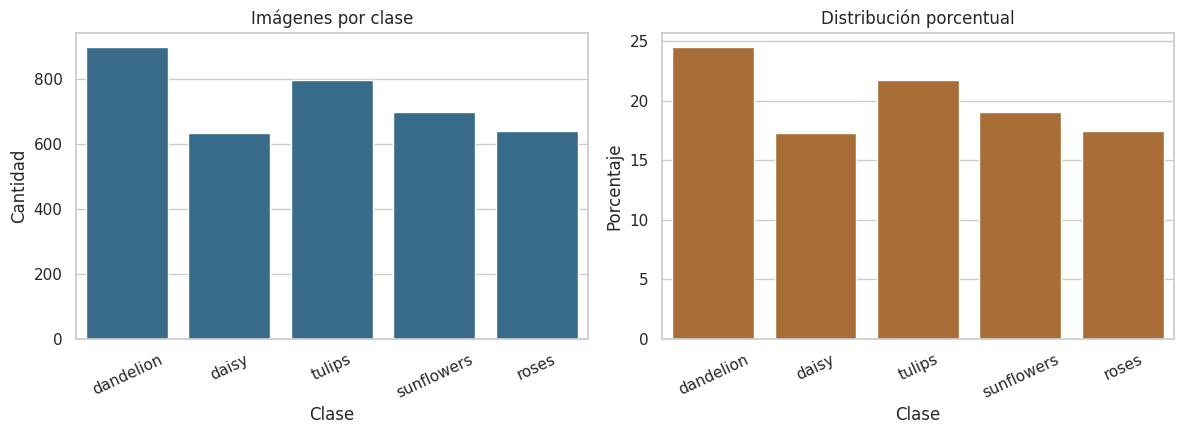

In [6]:
conteo = pd.Series(etiquetas).value_counts().sort_index()
df_clases = pd.DataFrame({
    "indice": conteo.index.astype(int),
    "clase": [nombres_clases[int(indice)] for indice in conteo.index],
    "nombre": [etiqueta_visible(indice) for indice in conteo.index],
    "imagenes": conteo.to_numpy(dtype=int),
})
df_clases["porcentaje"] = 100.0 * df_clases["imagenes"] / df_clases["imagenes"].sum()

print(f"Imágenes contabilizadas: {int(df_clases['imagenes'].sum())}")
print("Nombres oficiales:", ", ".join(nombres_clases))
display(df_clases.style.format({"porcentaje": "{:.2f}"}))

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=df_clases, x="clase", y="imagenes", color="#2a6f97", ax=ejes[0])
sns.barplot(data=df_clases, x="clase", y="porcentaje", color="#bc6c25", ax=ejes[1])
ejes[0].set_title("Imágenes por clase")
ejes[0].set_xlabel("Clase")
ejes[0].set_ylabel("Cantidad")
ejes[1].set_title("Distribución porcentual")
ejes[1].set_xlabel("Clase")
ejes[1].set_ylabel("Porcentaje")
for eje in ejes:
    eje.tick_params(axis="x", rotation=25)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "distribucion_clases.png", bbox_inches="tight")
plt.show()


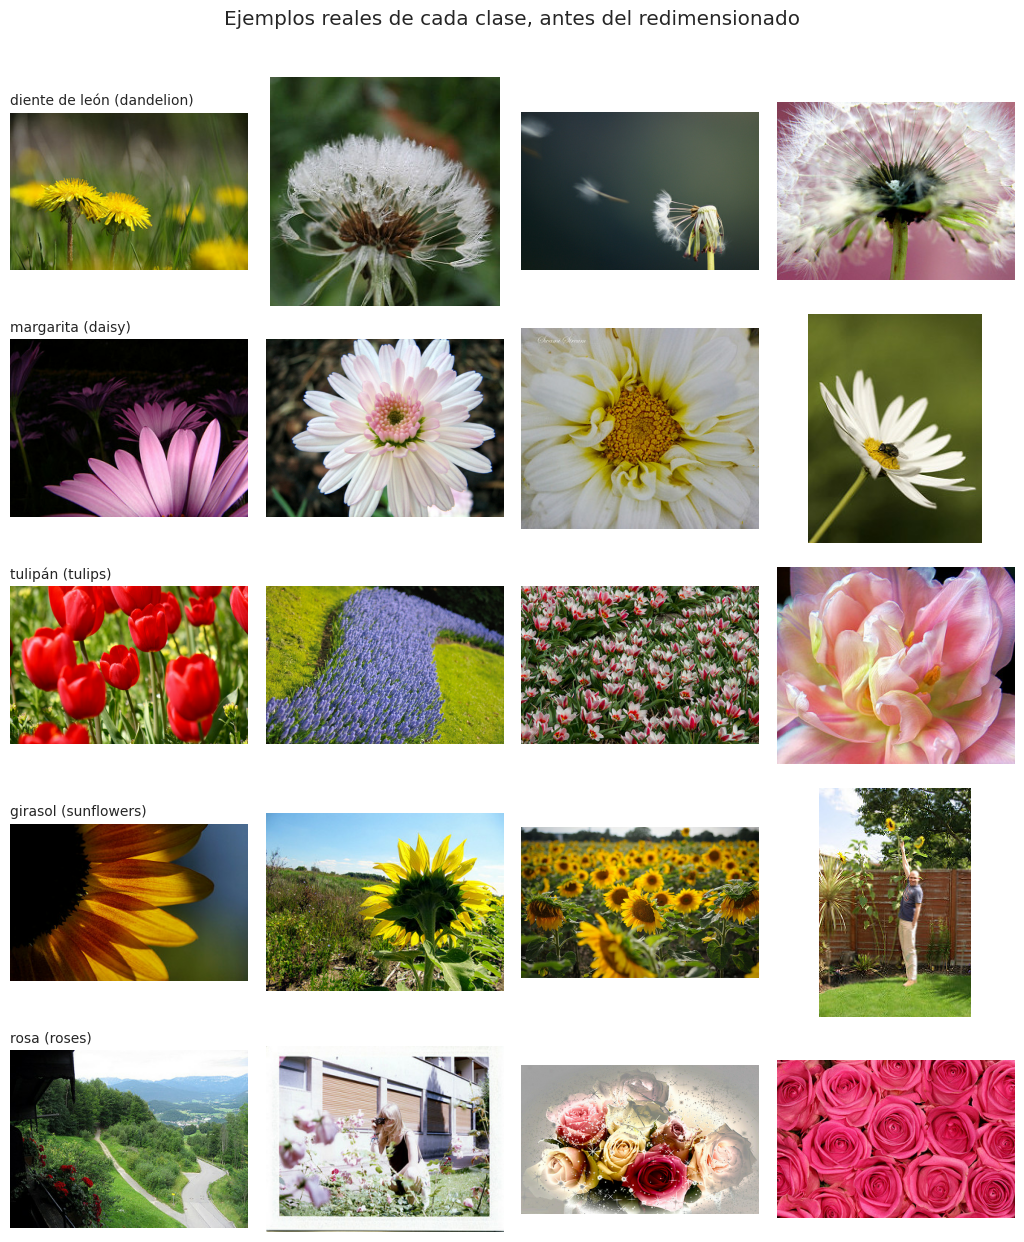

Etiquetas de los primeros ocho registros, en el orden de lectura:


,indice,etiqueta,clase,alto,ancho
0,0,2,tulips,333,500
1,1,3,sunflowers,212,320
2,2,3,sunflowers,240,320
3,3,4,roses,240,320
4,4,3,sunflowers,317,500
5,5,0,dandelion,212,320
6,6,0,dandelion,240,240
7,7,0,dandelion,333,500


In [7]:
filas = NUM_CLASES
columnas = EJEMPLOS_POR_CLASE
fig, ejes = plt.subplots(filas, columnas, figsize=(2.6 * columnas, 2.5 * filas))
for fila in range(filas):
    imagenes_de_la_clase = ejemplos_clase[fila]
    for columna in range(columnas):
        eje = ejes[fila, columna]
        if columna < len(imagenes_de_la_clase):
            eje.imshow(imagenes_de_la_clase[columna])
        eje.axis("off")
        if columna == 0:
            eje.set_title(etiqueta_visible(fila), loc="left", fontsize=10)
fig.suptitle("Ejemplos reales de cada clase, antes del redimensionado", y=1.01)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "ejemplos_clases.png", bbox_inches="tight")
plt.show()

print("Etiquetas de los primeros ocho registros, en el orden de lectura:")
vista_inicial = pd.DataFrame({
    "indice": np.arange(8),
    "etiqueta": etiquetas[:8],
    "clase": [nombres_clases[int(valor)] for valor in etiquetas[:8]],
    "alto": alturas[:8],
    "ancho": anchos[:8],
})
display(vista_inicial)


Resumen de las dimensiones originales, en píxeles:


,alto,ancho,relacion_ancho_alto
count,3670.00,3670.00,3670.00
mean,271.79,365.06,1.33
std,51.74,116.89,0.29
min,159.00,143.00,0.60
25%,240.00,320.00,1.26
50%,240.00,320.00,1.34
75%,333.00,500.00,1.50
max,442.00,1024.00,5.48


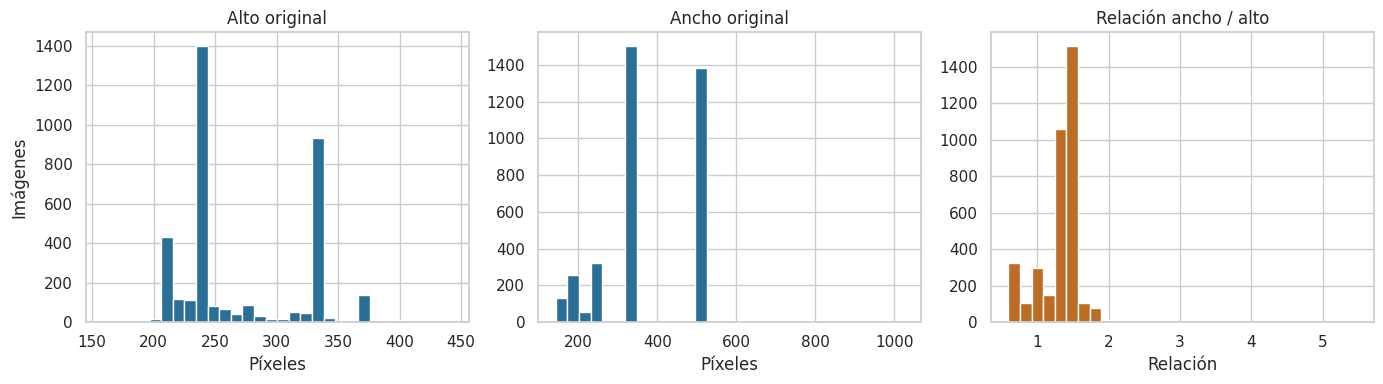

Se contabilizaron 3670 imágenes en 5 clases. La clase más frecuente es dandelion con 898 imágenes (24.5 %). La menos frecuente es daisy con 633 imágenes (17.2 %). La mayor frecuencia multiplica por 1.42 a la menor.
La diferencia entre clases es moderada. Aun así, el entrenamiento usará pesos de clase calculados únicamente con la partición de entrenamiento.
El alto mediano es 240 px y el ancho mediano es 320 px (mínimos 159×143, máximos 442×1024). El 92.7 % de las fotografías se aleja más de un 5 % de la relación cuadrada. El 26.6 % tiene su lado menor por debajo de 224 px. Esas imágenes se interpolan al llevarlas al tamaño de las redes. El relleno conserva la proporción y evita deformar pétalos y tallos.


In [8]:
df_dimensiones = pd.DataFrame({
    "alto": alturas,
    "ancho": anchos,
    "clase": [nombres_clases[int(valor)] for valor in etiquetas],
})
df_dimensiones["relacion_ancho_alto"] = df_dimensiones["ancho"] / df_dimensiones["alto"]
df_dimensiones["lado_menor"] = np.minimum(df_dimensiones["alto"], df_dimensiones["ancho"])

print("Resumen de las dimensiones originales, en píxeles:")
display(df_dimensiones[["alto", "ancho", "relacion_ancho_alto"]].describe().round(2))

fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
ejes[0].hist(df_dimensiones["alto"], bins=30, color="#2a6f97")
ejes[0].set_title("Alto original")
ejes[0].set_xlabel("Píxeles")
ejes[0].set_ylabel("Imágenes")
ejes[1].hist(df_dimensiones["ancho"], bins=30, color="#2a6f97")
ejes[1].set_title("Ancho original")
ejes[1].set_xlabel("Píxeles")
ejes[2].hist(df_dimensiones["relacion_ancho_alto"], bins=30, color="#bc6c25")
ejes[2].set_title("Relación ancho / alto")
ejes[2].set_xlabel("Relación")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "dimensiones.png", bbox_inches="tight")
plt.show()


def interpretar_exploracion(tabla_clases, tabla_dimensiones):
    total = int(tabla_clases["imagenes"].sum())
    fila_mayor = tabla_clases.loc[tabla_clases["imagenes"].idxmax()]
    fila_menor = tabla_clases.loc[tabla_clases["imagenes"].idxmin()]
    razon = float(fila_mayor["imagenes"] / fila_menor["imagenes"])
    relacion = tabla_dimensiones["relacion_ancho_alto"]
    porcentaje_no_cuadradas = float((relacion.sub(1.0).abs() > 0.05).mean() * 100)
    porcentaje_bajo_224 = float((tabla_dimensiones["lado_menor"] < TAMANO_IMAGEN[0]).mean() * 100)
    print(
        f"Se contabilizaron {total} imágenes en {len(tabla_clases)} clases. "
        f"La clase más frecuente es {fila_mayor['clase']} con {int(fila_mayor['imagenes'])} imágenes "
        f"({fila_mayor['porcentaje']:.1f} %). La menos frecuente es {fila_menor['clase']} con "
        f"{int(fila_menor['imagenes'])} imágenes ({fila_menor['porcentaje']:.1f} %). "
        f"La mayor frecuencia multiplica por {razon:.2f} a la menor."
    )
    if razon < 1.5:
        print(
            "La diferencia entre clases es moderada. Aun así, el entrenamiento usará pesos de clase "
            "calculados únicamente con la partición de entrenamiento."
        )
    elif razon < 3:
        print(
            "Hay un desbalance apreciable. Los pesos de clase, estimados solo en entrenamiento, "
            "evitan que la accuracy quede dominada por las clases más numerosas."
        )
    else:
        print(
            "El desbalance es marcado. Los pesos de clase son parte del entrenamiento para que "
            "las clases minoritarias influyan en la pérdida."
        )
    print(
        f"El alto mediano es {tabla_dimensiones['alto'].median():.0f} px y el ancho mediano es "
        f"{tabla_dimensiones['ancho'].median():.0f} px "
        f"(mínimos {int(tabla_dimensiones['alto'].min())}×{int(tabla_dimensiones['ancho'].min())}, "
        f"máximos {int(tabla_dimensiones['alto'].max())}×{int(tabla_dimensiones['ancho'].max())}). "
        f"El {porcentaje_no_cuadradas:.1f} % de las fotografías se aleja más de un 5 % de la relación cuadrada. "
        f"El {porcentaje_bajo_224:.1f} % tiene su lado menor por debajo de {TAMANO_IMAGEN[0]} px. "
        "Esas imágenes se interpolan al llevarlas al tamaño de las redes. El relleno conserva la proporción "
        "y evita deformar pétalos y tallos."
    )


interpretar_exploracion(df_clases, df_dimensiones)


## Sección 5. Particionamiento y preprocesamiento

`tf_flowers` publica un solo split. La partición de trabajo se construye aquí, con semilla fija.

1. Se numeran las imágenes en el orden de lectura, con `shuffle_files=False`, para que los índices sean estables.
2. `train_test_split` separa primero el 70 % de entrenamiento y el 30 % restante, con `stratify`.
3. Ese 30 % se divide por la mitad, otra vez de forma estratificada. El resultado es 70 % entrenamiento, 15 % validación y 15 % prueba.
4. Se comprueba que los tres conjuntos son disjuntos, que su unión es el dataset completo y que todas las clases aparecen en los tres.

La validación guía EarlyStopping, el checkpoint y la elección del modelo. La prueba solo se usa en la sección 10.

El preprocesamiento de VGG16 y el de ResNet50, en Keras, siguen la convención Caffe de ImageNet: convierten RGB a BGR y restan las medias de los canales. No se divide entre 255 ni se reescala a \([-1, 1]\). Esos reescalados pertenecen a otras familias, como Xception o EfficientNet, y desplazarían las activaciones respecto de los pesos cargados. Cada experimento llama a la función de su arquitectura. Una celda mide si, en la versión instalada, ambas funciones coinciden numéricamente.

El aumento de datos se aplica solo al entrenamiento y es moderado, porque el color y la forma distinguen a estas flores: volteo horizontal, rotación de hasta unos 18 grados (`factor=0.05` de la circunferencia), un cambio de brillo de ±18 niveles y un contraste entre 0.9 y 1.1. No se altera el tono. Validación y prueba conservan la imagen redimensionada.

Las tuberías de entrenamiento barajan el conjunto completo y hacen `prefetch`. Las de evaluación no se barajan, para que el orden coincida con los índices. El lote de evaluación queda en 32; en modo inferencia, con BatchNormalization fija, el tamaño de lote no cambia la predicción de una imagen. El lote de entrenamiento sí forma parte de la malla porque cambia la dinámica del optimizador.


In [9]:
def particion_estratificada(etiquetas_array):
    indices = np.arange(len(etiquetas_array))
    proporcion_temporal = 1.0 - PROPORCION_ENTRENAMIENTO
    idx_train, idx_temp, _, y_temp = train_test_split(
        indices,
        etiquetas_array,
        test_size=proporcion_temporal,
        stratify=etiquetas_array,
        random_state=SEMILLA,
    )
    proporcion_prueba_en_temporal = PROPORCION_PRUEBA / (PROPORCION_VALIDACION + PROPORCION_PRUEBA)
    idx_val, idx_test = train_test_split(
        idx_temp,
        test_size=proporcion_prueba_en_temporal,
        stratify=y_temp,
        random_state=SEMILLA,
    )
    return (
        np.asarray(idx_train, dtype=np.int64),
        np.asarray(idx_val, dtype=np.int64),
        np.asarray(idx_test, dtype=np.int64),
    )


idx_entrenamiento, idx_validacion, idx_prueba = particion_estratificada(etiquetas)

conjunto_entrenamiento = set(idx_entrenamiento.tolist())
conjunto_validacion = set(idx_validacion.tolist())
conjunto_prueba = set(idx_prueba.tolist())
if conjunto_entrenamiento & conjunto_validacion:
    raise RuntimeError("Entrenamiento y validación comparten imágenes.")
if conjunto_entrenamiento & conjunto_prueba:
    raise RuntimeError("Entrenamiento y prueba comparten imágenes.")
if conjunto_validacion & conjunto_prueba:
    raise RuntimeError("Validación y prueba comparten imágenes.")
union = conjunto_entrenamiento | conjunto_validacion | conjunto_prueba
if union != set(range(len(etiquetas))):
    raise RuntimeError("La unión de las particiones no recupera todas las imágenes.")

filas_particion = []
for nombre_particion, indices_particion in (
    ("entrenamiento", idx_entrenamiento),
    ("validacion", idx_validacion),
    ("prueba", idx_prueba),
):
    conteo_particion = pd.Series(etiquetas[indices_particion]).value_counts().sort_index()
    fila = {
        "particion": nombre_particion,
        "imagenes": int(len(indices_particion)),
        "porcentaje": 100.0 * len(indices_particion) / len(etiquetas),
    }
    for indice_clase, nombre_clase in enumerate(nombres_clases):
        fila[nombre_clase] = int(conteo_particion.get(indice_clase, 0))
    filas_particion.append(fila)
    if (conteo_particion.reindex(range(NUM_CLASES), fill_value=0) == 0).any():
        raise RuntimeError(f"La partición {nombre_particion} dejó una clase sin ejemplos.")

df_particion = pd.DataFrame(filas_particion)
display(df_particion.style.format({"porcentaje": "{:.2f}"}))
print(
    "Tamaños:",
    len(idx_entrenamiento),
    "entrenamiento,",
    len(idx_validacion),
    "validación,",
    len(idx_prueba),
    "prueba.",
)

pesos_balanceados = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(NUM_CLASES),
    y=etiquetas[idx_entrenamiento],
)
pesos_clase = {int(clase): float(peso) for clase, peso in enumerate(pesos_balanceados)}
print("Pesos de clase estimados solo con entrenamiento:", pesos_clase)


,particion,imagenes,porcentaje,dandelion,daisy,tulips,sunflowers,roses
0,entrenamiento,2568,69.97,628,443,559,489,449
1,validacion,551,15.01,135,95,120,105,96
2,prueba,551,15.01,135,95,120,105,96


Tamaños: 2568 entrenamiento, 551 validación, 551 prueba.
Pesos de clase estimados solo con entrenamiento: {0: 0.8178343949044586, 1: 1.1593679458239277, 2: 0.918783542039356, 3: 1.0503067484662576, 4: 1.1438752783964365}


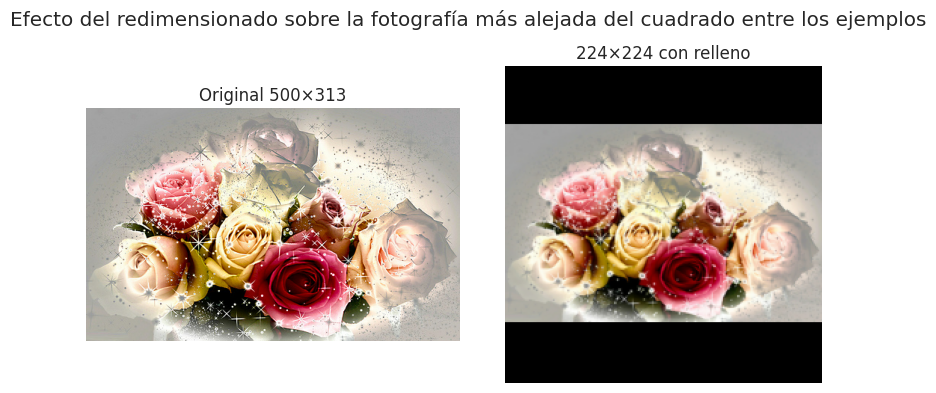

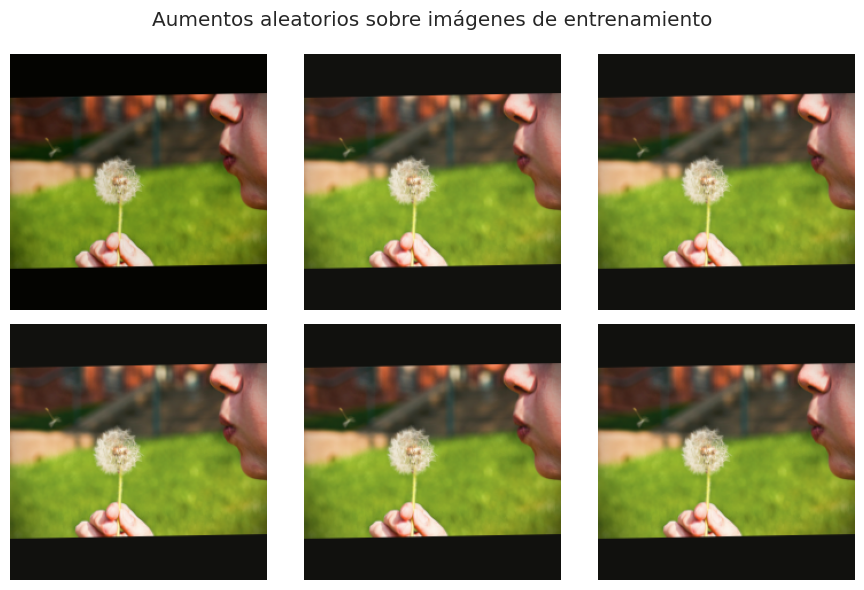

Diferencia máxima entre preprocess_input de VGG16 y ResNet50: 0.000000
Diferencia máxima frente a dividir entre 255: 123.68
Rango después de preprocess_input de VGG16: [-123.68, 96.32]
Una diferencia nula entre VGG16 y ResNet50 confirma que esta versión de Keras usa la misma convención Caffe en ambos módulos. El entrenamiento invoca cada función desde su módulo para mantener el emparejamiento arquitectura-preproceso.


In [10]:
def crear_pipeline(indices, tamano_lote, funcion_preproceso, entrenar):
    indices = np.asarray(indices, dtype=np.int64)
    dataset = tf.data.Dataset.from_tensor_slices((
        imagenes_224[indices],
        etiquetas[indices].astype(np.int32),
    ))
    opciones = tf.data.Options()
    if hasattr(opciones, "deterministic"):
        opciones.deterministic = True
    else:
        opciones.experimental_deterministic = True
    dataset = dataset.with_options(opciones)

    if entrenar:
        dataset = dataset.shuffle(
            buffer_size=len(indices),
            seed=SEMILLA,
            reshuffle_each_iteration=True,
        )
        volteo = keras.layers.RandomFlip("horizontal", seed=SEMILLA)
        rotacion = keras.layers.RandomRotation(0.05, fill_mode="reflect", seed=SEMILLA)
        ejemplo = tf.zeros((1, TAMANO_IMAGEN[0], TAMANO_IMAGEN[1], 3))
        _ = rotacion(volteo(ejemplo), training=True)

        def aumentar(imagen, etiqueta):
            imagen = tf.cast(imagen, tf.float32)
            imagen = tf.expand_dims(imagen, 0)
            imagen = volteo(imagen, training=True)
            imagen = rotacion(imagen, training=True)
            imagen = tf.squeeze(imagen, 0)
            imagen = tf.image.random_brightness(imagen, max_delta=18.0)
            imagen = tf.image.random_contrast(imagen, lower=0.9, upper=1.1)
            imagen = tf.clip_by_value(imagen, 0.0, 255.0)
            return imagen, etiqueta

        dataset = dataset.map(aumentar, num_parallel_calls=tf.data.AUTOTUNE)
    else:
        def a_flotante(imagen, etiqueta):
            return tf.cast(imagen, tf.float32), etiqueta

        dataset = dataset.map(a_flotante, num_parallel_calls=tf.data.AUTOTUNE)

    def preprocesar(imagen, etiqueta):
        return funcion_preproceso(imagen), etiqueta

    dataset = dataset.map(preprocesar, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(int(tamano_lote), drop_remainder=False)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset


def imagen_mas_alargada(ejemplos):
    elegida = None
    mayor_diferencia = -1.0
    for lista in ejemplos.values():
        for imagen in lista:
            alto, ancho = imagen.shape[:2]
            diferencia = abs((ancho / alto) - 1.0)
            if diferencia > mayor_diferencia:
                mayor_diferencia = diferencia
                elegida = imagen
    return elegida


imagen_geometrica = imagen_mas_alargada(ejemplos_clase)
redimensionada_vista = tf.image.resize_with_pad(
    imagen_geometrica,
    TAMANO_IMAGEN[0],
    TAMANO_IMAGEN[1],
    method="bilinear",
    antialias=True,
)
redimensionada_vista = tf.cast(
    tf.clip_by_value(tf.round(redimensionada_vista), 0, 255),
    tf.uint8,
).numpy()

fig, ejes = plt.subplots(1, 2, figsize=(8, 4))
ejes[0].imshow(imagen_geometrica)
ejes[0].set_title(f"Original {imagen_geometrica.shape[1]}×{imagen_geometrica.shape[0]}")
ejes[1].imshow(redimensionada_vista)
ejes[1].set_title("224×224 con relleno")
for eje in ejes:
    eje.axis("off")
fig.suptitle("Efecto del redimensionado sobre la fotografía más alejada del cuadrado entre los ejemplos")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "redimensionado.png", bbox_inches="tight")
plt.show()

fig, ejes = plt.subplots(2, 3, figsize=(9, 6))
for eje in ejes.ravel():
    lote_imagenes, _ = next(iter(crear_pipeline(idx_entrenamiento[:32], 1, lambda imagen: imagen, True)))
    eje.imshow(np.clip(lote_imagenes[0].numpy(), 0, 255).astype("uint8"))
    eje.axis("off")
fig.suptitle("Aumentos aleatorios sobre imágenes de entrenamiento")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "aumento_datos.png", bbox_inches="tight")
plt.show()

muestra_preproceso = tf.cast(imagenes_224[int(idx_entrenamiento[0])], tf.float32)
salida_vgg = keras.applications.vgg16.preprocess_input(muestra_preproceso)
salida_resnet = keras.applications.resnet50.preprocess_input(muestra_preproceso)
diferencia_arquitecturas = float(tf.reduce_max(tf.abs(salida_vgg - salida_resnet)).numpy())
diferencia_dividir_255 = float(tf.reduce_max(tf.abs(salida_vgg - (muestra_preproceso / 255.0))).numpy())
print(f"Diferencia máxima entre preprocess_input de VGG16 y ResNet50: {diferencia_arquitecturas:.6f}")
print(f"Diferencia máxima frente a dividir entre 255: {diferencia_dividir_255:.2f}")
print(
    "Rango después de preprocess_input de VGG16: "
    f"[{float(tf.reduce_min(salida_vgg)):.2f}, {float(tf.reduce_max(salida_vgg)):.2f}]"
)
print(
    "Una diferencia nula entre VGG16 y ResNet50 confirma que esta versión de Keras "
    "usa la misma convención Caffe en ambos módulos. El entrenamiento invoca cada función "
    "desde su módulo para mantener el emparejamiento arquitectura-preproceso."
)


In [11]:
EXPERIMENTOS = []
HISTORIALES = {}
MEJOR_EXPERIMENTO = None
RESULTADOS_PRUEBA = None
print("Registro de experimentos inicializado. El conjunto de prueba no entra en este registro.")


Registro de experimentos inicializado. El conjunto de prueba no entra en este registro.


## Sección 6. Modelo VGG16

VGG16 (Simonyan y Zisserman, 2015) apila convoluciones pequeñas de 3×3. En Keras Applications, la versión con la cabeza de ImageNet tiene 138.4 millones de parámetros y un top-1 de 71.3 % en la validación de ImageNet. Esas cifras describen ImageNet, no `tf_flowers`. Con `include_top=False` la red termina en un mapa de 7×7×512 cuando la entrada es 224×224.

La cabeza clasificadora es:

`GlobalAveragePooling2D → Dropout → Dense(5, softmax)`

En la primera fase la base queda congelada. Solo se entrenan los pesos de la capa densa: \(512 \times 5 + 5 = 2565\) parámetros. El optimizador es Adam con tasa \(10^{-3}\), pérdida `sparse_categorical_crossentropy` y métrica de accuracy. EarlyStopping y ModelCheckpoint observan el macro-F1 de validación, calculado al cierre de cada época con scikit-learn sobre todas las imágenes de validación. EarlyStopping restaura los pesos de la mejor época.

En la segunda fase se descongela el bloque 5 (`block5_conv1`, `block5_conv2` y `block5_conv3`). El modelo se **vuelve a compilar** con Adam y tasa \(10^{-5}\). VGG16 no contiene BatchNormalization; la comprobación de esas capas corresponde a ResNet50 y, en VGG, debe informar que no existen.

La configuración que se entrena a continuación forma parte de la malla: el primer tamaño de lote y el primer dropout de las listas activas. En el modo completo eso es lote 16 y dropout 0.3, una combinación más contenida en memoria para VGG16. La sección 8 recorre el resto sin repetir este identificador. Si un lote de 32 agota la memoria de la GPU, deje `TAMANOS_LOTE = [16]` y vuelva a ejecutar desde la configuración: la comparación sigue incluyendo las dos arquitecturas y los dos valores de dropout. Las curvas marcan con una línea vertical el paso de la cabeza al fine-tuning.



Experimento vgg16_lote16_dropout0.30
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Fase 1. Base convolucional congelada.
Capas de la base con pesos entrenables: 0
Esta base no tiene capas BatchNormalization.


Model: "clasificador_vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ promedio_global                 │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ abandono (Dropout)              │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clase (Dense)                   │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,717,253 (56.14 MB)

 Trainable params: 2,565 (10.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 44s 233ms/step - accuracy: 0.4696 - loss: 2.7629 - val_accuracy: 0.6788 - val_loss: 1.2034 - val_macro_f1: 0.6691
Epoch 2/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 30s 189ms/step - accuracy: 0.6600 - loss: 1.3203 - val_accuracy: 0.8004 - val_loss: 0.7488 - val_macro_f1: 0.7979
Epoch 3/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 41s 190ms/step - accuracy: 0.7395 - loss: 0.9172 - val_accuracy: 0.8385 - val_loss: 0.6397 - val_macro_f1: 0.8373
Epoch 4/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 30s 189ms/step - accuracy: 0.7718 - loss: 0.7763 - val_accuracy: 0.8367 - val_loss: 0.5907 - val_macro_f1: 0.8348
Epoch 5/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 42s 193ms/step - accuracy: 0.7913 - loss: 0.6683 - val_accuracy: 0.8475 - val_loss: 0.5534 - val_macro_f1: 0.8469
Epoch 6/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 32s 199ms/step - accuracy: 0.8033 - loss: 0.5982 - val_accuracy: 0.8730 - val_loss: 0.5116 - val_macro_f1: 0.8726
Restoring model weights from the end of the best epoch: 6.
Fase 2. Última etapa de

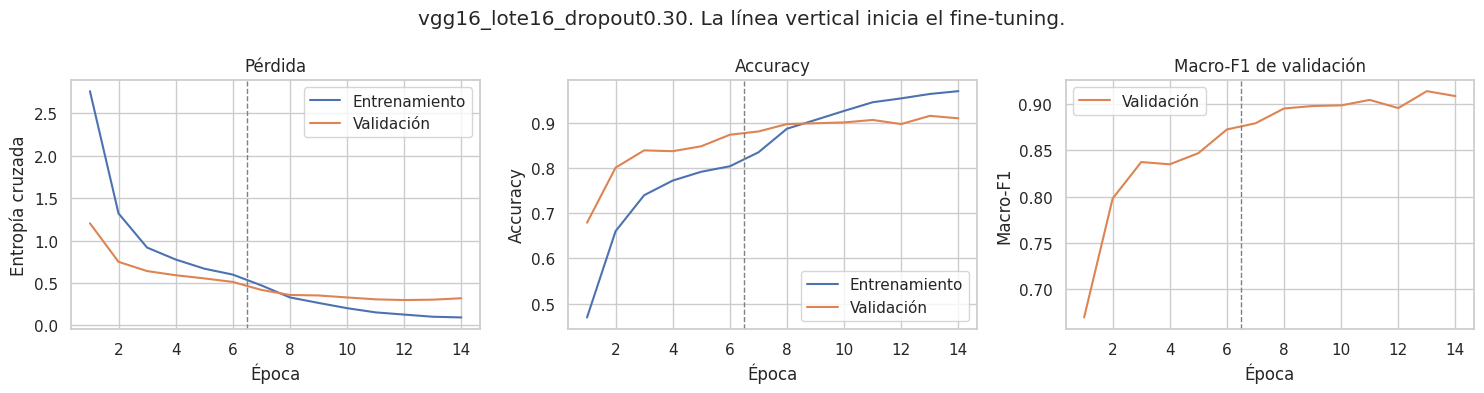

{'id': 'vgg16_lote16_dropout0.30',
 'arquitectura': 'vgg16',
 'tamano_lote': 16,
 'dropout': 0.3,
 'tasa_cabeza': 0.001,
 'tasa_ajuste': 1e-05,
 'epocas_cabeza': 6,
 'mejor_epoca_cabeza': 6,
 'epocas_ajuste': 8,
 'mejor_epoca_ajuste': 7,
 'accuracy_validacion_cabeza': 0.8729582577132486,
 'macro_f1_validacion_cabeza': 0.8725576630776807,
 'accuracy_entrenamiento': 0.9630062580108643,
 'accuracy_validacion': 0.9147005444646098,
 'macro_f1_validacion': 0.9140051562969187,
 'perdida_validacion': 0.3022325336933136,
 'tiempo_segundos': 509.9274910450001,
 'parametros_entrenables_cabeza': 2565,
 'parametros_entrenables_ajuste': 7081989,
 'capas_entrenables_ajuste': 3,
 'ruta_modelo': 'resultados/checkpoints/vgg16_lote16_dropout0.30.keras'}

In [12]:
def numero_parametros(lista_pesos):
    total = 0
    for tensor in lista_pesos:
        total += int(np.prod(tensor.shape))
    return total


def construir_modelo(arquitectura, dropout):
    forma = (TAMANO_IMAGEN[0], TAMANO_IMAGEN[1], 3)
    if arquitectura == "vgg16":
        base = keras.applications.VGG16(
            include_top=False,
            weights="imagenet",
            input_shape=forma,
        )
        preproceso = keras.applications.vgg16.preprocess_input
        canales_finales = 512
    elif arquitectura == "resnet50":
        base = keras.applications.ResNet50(
            include_top=False,
            weights="imagenet",
            input_shape=forma,
        )
        preproceso = keras.applications.resnet50.preprocess_input
        canales_finales = 2048
    else:
        raise ValueError(f"Arquitectura no contemplada: {arquitectura}")

    base.trainable = False
    entradas = keras.Input(shape=forma, name="imagen")
    # training=False deja la base en inferencia. En ResNet50 evita que BatchNormalization
    # actualice sus estadísticas al descongelar las convoluciones.
    mapa = base(entradas, training=False)
    vector = keras.layers.GlobalAveragePooling2D(name="promedio_global")(mapa)
    regularizado = keras.layers.Dropout(float(dropout), name="abandono")(vector)
    salidas = keras.layers.Dense(NUM_CLASES, activation="softmax", name="clase")(regularizado)
    modelo = keras.Model(entradas, salidas, name=f"clasificador_{arquitectura}")
    return modelo, base, preproceso, canales_finales


def descongelar_etapa_final(base, arquitectura):
    base.trainable = True
    for capa in base.layers:
        if arquitectura == "vgg16":
            capa.trainable = capa.name.startswith("block5")
        elif arquitectura == "resnet50":
            capa.trainable = capa.name.startswith("conv5_block")
        else:
            raise ValueError(arquitectura)
        if isinstance(capa, keras.layers.BatchNormalization):
            capa.trainable = False


def describir_entrenabilidad(base, titulo):
    entrenables = []
    capas_bn = []
    for capa in base.layers:
        if isinstance(capa, keras.layers.BatchNormalization):
            capas_bn.append(capa)
        if capa.trainable and len(capa.weights) > 0:
            entrenables.append(capa.name)
    print(titulo)
    print(f"Capas de la base con pesos entrenables: {len(entrenables)}")
    for nombre in entrenables:
        print(" ", nombre)
    if capas_bn:
        activas = sum(1 for capa in capas_bn if capa.trainable)
        print(f"Capas BatchNormalization: {len(capas_bn)}. Entrenables: {activas}.")
        if activas != 0:
            raise RuntimeError("Las capas BatchNormalization deben permanecer congeladas.")
    else:
        print("Esta base no tiene capas BatchNormalization.")
    return entrenables


def predecir_conjunto(modelo, dataset):
    verdaderas = []
    probabilidades = []
    for lote_x, lote_y in dataset:
        probabilidad = modelo(lote_x, training=False)
        probabilidades.append(np.asarray(probabilidad))
        verdaderas.append(np.asarray(lote_y))
    y_true = np.concatenate(verdaderas).astype(int)
    y_prob = np.concatenate(probabilidades)
    y_pred = np.argmax(y_prob, axis=1).astype(int)
    return y_true, y_pred, y_prob


def calcular_metricas(y_true, y_pred):
    accuracy = float(accuracy_score(y_true, y_pred))
    macro_f1 = float(f1_score(
        y_true,
        y_pred,
        labels=list(range(NUM_CLASES)),
        average="macro",
        zero_division=0,
    ))
    return accuracy, macro_f1


class RegistroMacroF1(keras.callbacks.Callback):
    def __init__(self, dataset_val):
        super().__init__()
        self.dataset_val = dataset_val
        self.valores = []

    def on_epoch_end(self, epoch, logs=None):
        y_true, y_pred, _ = predecir_conjunto(self.model, self.dataset_val)
        valor = float(f1_score(
            y_true,
            y_pred,
            labels=list(range(NUM_CLASES)),
            average="macro",
            zero_division=0,
        ))
        self.valores.append(valor)
        if logs is not None:
            logs["val_macro_f1"] = valor


def historial_a_dict(history, f1_valores):
    datos = {
        clave: [float(valor) for valor in serie]
        for clave, serie in history.history.items()
    }
    datos["val_macro_f1"] = [float(valor) for valor in f1_valores]
    return datos


def guardar_registro():
    pd.DataFrame(EXPERIMENTOS).to_csv(
        RUTA_RESULTADOS / "resumen_experimentos.csv",
        index=False,
        encoding="utf-8",
    )
    with open(RUTA_RESULTADOS / "historiales.json", "w", encoding="utf-8") as archivo:
        json.dump(HISTORIALES, archivo, ensure_ascii=False)


def graficar_curvas(id_exp):
    cabeza = HISTORIALES[id_exp]["cabeza"]
    ajuste = HISTORIALES[id_exp]["ajuste"]
    corte = len(cabeza["loss"])

    def unir(clave):
        return list(cabeza.get(clave, [])) + list(ajuste.get(clave, []))

    epocas = np.arange(1, len(unir("loss")) + 1)
    fig, ejes = plt.subplots(1, 3, figsize=(15, 4))
    ejes[0].plot(epocas, unir("loss"), label="Entrenamiento")
    ejes[0].plot(epocas, unir("val_loss"), label="Validación")
    ejes[0].set_title("Pérdida")
    ejes[0].set_ylabel("Entropía cruzada")
    ejes[1].plot(epocas, unir("accuracy"), label="Entrenamiento")
    ejes[1].plot(epocas, unir("val_accuracy"), label="Validación")
    ejes[1].set_title("Accuracy")
    ejes[1].set_ylabel("Accuracy")
    ejes[2].plot(epocas, unir("val_macro_f1"), color="C1", label="Validación")
    ejes[2].set_title("Macro-F1 de validación")
    ejes[2].set_ylabel("Macro-F1")
    for eje in ejes:
        eje.axvline(corte + 0.5, color="gray", linestyle="--", linewidth=1)
        eje.set_xlabel("Época")
        eje.legend()
    fig.suptitle(f"{id_exp}. La línea vertical inicia el fine-tuning.")
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / f"curvas_{id_exp}.png", bbox_inches="tight")
    plt.show()


def comentar_experimento(registro):
    delta = registro["macro_f1_validacion"] - registro["macro_f1_validacion_cabeza"]
    brecha = registro["accuracy_entrenamiento"] - registro["accuracy_validacion"]
    print(
        f"{registro['id']}: macro-F1 de validación {registro['macro_f1_validacion']:.4f} "
        f"tras el fine-tuning ({delta:+.4f} frente a la cabeza). "
        f"En la mejor época de la fase 2, la accuracy de entrenamiento fue "
        f"{registro['accuracy_entrenamiento']:.4f} y la de validación "
        f"{registro['accuracy_validacion']:.4f} (diferencia {brecha:+.4f}). "
        f"Tiempo del experimento: {registro['tiempo_segundos'] / 60:.1f} min."
    )


def identificador(arquitectura, tamano_lote, dropout):
    return f"{arquitectura}_lote{int(tamano_lote)}_dropout{float(dropout):.2f}"


def ejecutar_experimento(arquitectura, tamano_lote, dropout):
    id_exp = identificador(arquitectura, tamano_lote, dropout)
    if conjunto_entrenamiento & conjunto_prueba:
        raise RuntimeError("El entrenamiento recibiría índices de prueba.")

    print("\n" + "=" * 78)
    print("Experimento", id_exp)
    print("=" * 78)

    fijar_semilla(SEMILLA)
    keras.backend.clear_session()
    gc.collect()

    modelo, base, preproceso, canales_finales = construir_modelo(arquitectura, dropout)
    describir_entrenabilidad(base, "Fase 1. Base convolucional congelada.")
    parametros_cabeza = numero_parametros(modelo.trainable_weights)
    esperados_cabeza = canales_finales * NUM_CLASES + NUM_CLASES
    if parametros_cabeza != esperados_cabeza:
        raise RuntimeError(
            f"La cabeza de {arquitectura} debería tener {esperados_cabeza} parámetros "
            f"entrenables y tiene {parametros_cabeza}."
        )

    ds_train = crear_pipeline(idx_entrenamiento, tamano_lote, preproceso, True)
    ds_val = crear_pipeline(idx_validacion, tamano_lote, preproceso, False)
    ds_val_metricas = crear_pipeline(idx_validacion, 32, preproceso, False)
    ruta_modelo = RUTA_CHECKPOINTS / f"{id_exp}.keras"

    modelo.summary()
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=TASA_CABEZA),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    inicio = time.perf_counter()
    f1_cabeza_epocas = RegistroMacroF1(ds_val_metricas)
    historial_cabeza = modelo.fit(
        ds_train,
        validation_data=ds_val,
        epochs=EPOCAS_CABEZA,
        class_weight=pesos_clase,
        callbacks=[
            f1_cabeza_epocas,
            keras.callbacks.ModelCheckpoint(
                filepath=str(ruta_modelo),
                monitor="val_macro_f1",
                mode="max",
                save_best_only=True,
                verbose=0,
            ),
            keras.callbacks.EarlyStopping(
                monitor="val_macro_f1",
                mode="max",
                patience=PACIENCIA,
                restore_best_weights=True,
                verbose=1,
            ),
        ],
        verbose=1,
    )
    y_val_cabeza, prediccion_cabeza, _ = predecir_conjunto(modelo, ds_val_metricas)
    accuracy_cabeza, macro_f1_cabeza = calcular_metricas(y_val_cabeza, prediccion_cabeza)
    mejor_epoca_cabeza = int(np.argmax(f1_cabeza_epocas.valores)) + 1

    descongelar_etapa_final(base, arquitectura)
    entrenables = describir_entrenabilidad(base, "Fase 2. Última etapa descongelada.")
    if arquitectura == "vgg16" and not any(nombre.startswith("block5_conv") for nombre in entrenables):
        raise RuntimeError("No quedaron entrenables las convoluciones del bloque 5 de VGG16.")
    if arquitectura == "resnet50" and not any(nombre.startswith("conv5_block") for nombre in entrenables):
        raise RuntimeError("No quedó entrenable la etapa conv5 de ResNet50.")

    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=TASA_AJUSTE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    parametros_ajuste = numero_parametros(modelo.trainable_weights)
    if parametros_ajuste <= parametros_cabeza:
        parametros_ajuste = numero_parametros(base.trainable_weights) + parametros_cabeza
    if parametros_ajuste <= parametros_cabeza:
        raise RuntimeError("El fine-tuning no aumentó el número de parámetros entrenables.")
    f1_ajuste_epocas = RegistroMacroF1(ds_val_metricas)
    historial_ajuste = modelo.fit(
        ds_train,
        validation_data=ds_val,
        epochs=EPOCAS_AJUSTE,
        class_weight=pesos_clase,
        callbacks=[
            f1_ajuste_epocas,
            keras.callbacks.ModelCheckpoint(
                filepath=str(ruta_modelo),
                monitor="val_macro_f1",
                mode="max",
                save_best_only=True,
                verbose=0,
            ),
            keras.callbacks.EarlyStopping(
                monitor="val_macro_f1",
                mode="max",
                patience=PACIENCIA,
                restore_best_weights=True,
                verbose=1,
            ),
        ],
        verbose=1,
    )
    y_val_final, prediccion_final, _ = predecir_conjunto(modelo, ds_val_metricas)
    accuracy_val, macro_f1_val = calcular_metricas(y_val_final, prediccion_final)
    indice_mejor = int(np.argmax(f1_ajuste_epocas.valores))
    try:
        modelo.save(ruta_modelo, include_optimizer=False)
    except TypeError:
        modelo.save(ruta_modelo)
    tiempo = time.perf_counter() - inicio

    HISTORIALES[id_exp] = {
        "cabeza": historial_a_dict(historial_cabeza, f1_cabeza_epocas.valores),
        "ajuste": historial_a_dict(historial_ajuste, f1_ajuste_epocas.valores),
    }
    registro = {
        "id": id_exp,
        "arquitectura": arquitectura,
        "tamano_lote": int(tamano_lote),
        "dropout": float(dropout),
        "tasa_cabeza": float(TASA_CABEZA),
        "tasa_ajuste": float(TASA_AJUSTE),
        "epocas_cabeza": int(len(historial_cabeza.history["loss"])),
        "mejor_epoca_cabeza": int(mejor_epoca_cabeza),
        "epocas_ajuste": int(len(historial_ajuste.history["loss"])),
        "mejor_epoca_ajuste": int(indice_mejor + 1),
        "accuracy_validacion_cabeza": float(accuracy_cabeza),
        "macro_f1_validacion_cabeza": float(macro_f1_cabeza),
        "accuracy_entrenamiento": float(historial_ajuste.history["accuracy"][indice_mejor]),
        "accuracy_validacion": float(accuracy_val),
        "macro_f1_validacion": float(macro_f1_val),
        "perdida_validacion": float(historial_ajuste.history["val_loss"][indice_mejor]),
        "tiempo_segundos": float(tiempo),
        "parametros_entrenables_cabeza": int(parametros_cabeza),
        "parametros_entrenables_ajuste": int(parametros_ajuste),
        "capas_entrenables_ajuste": int(len(entrenables)),
        "ruta_modelo": str(ruta_modelo),
    }
    EXPERIMENTOS[:] = [fila for fila in EXPERIMENTOS if fila["id"] != id_exp]
    EXPERIMENTOS.append(registro)
    guardar_registro()
    comentar_experimento(registro)
    graficar_curvas(id_exp)

    keras.backend.clear_session()
    gc.collect()
    return registro


if ("vgg16", REF_LOTE, REF_DROPOUT) not in COMBINACIONES:
    raise RuntimeError("La configuración de referencia de VGG16 no pertenece a la malla.")

ejecutar_experimento("vgg16", REF_LOTE, REF_DROPOUT)


## Sección 7. Modelo ResNet50

ResNet50 (He, Zhang, Ren y Sun, 2016) introduce conexiones residuales. En la tabla de Keras Applications tiene 25.6 millones de parámetros y un top-1 de 74.9 % en ImageNet, de nuevo una referencia de ese dataset y no un resultado de flores. Con entrada 224×224 e `include_top=False`, el mapa final tiene 2048 canales. La cabeza nueva tiene \(2048 \times 5 + 5 = 10245\) parámetros.

El procedimiento es el mismo que en VGG16: mismos índices, mismo aumento, misma pérdida, mismas tasas, misma paciencia y la misma regla de selección. La diferencia de arquitectura se respeta en dos sitios. El preprocesamiento se toma de `keras.applications.resnet50.preprocess_input`. El fine-tuning descongela solo los bloques `conv5_block`, que forman la última etapa residual, incluidos sus atajos convolucionales.

ResNet50 incluye capas BatchNormalization. Esas capas quedan con `trainable=False` y la base se invoca con `training=False`, de modo que el fine-tuning conserva las medias y varianzas de ImageNet. Reestimarlas con lotes pequeños degrada las representaciones preentrenadas, como advierte la guía de transferencia de Keras. La celda de entrenamiento informa cuántas de esas capas existen y confirma que ninguna queda entrenable.

Al terminar, las curvas permiten comparar esta corrida de referencia con la de VGG16 antes de completar el resto de la malla.



Experimento resnet50_lote16_dropout0.30
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step
Fase 1. Base convolucional congelada.
Capas de la base con pesos entrenables: 0
Capas BatchNormalization: 53. Entrenables: 0.


Model: "clasificador_resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ promedio_global                 │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ abandono (Dropout)              │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clase (Dense)                   │ (None, 5)              │        10,245 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,597,957 (90.02 MB)

 Trainable params: 10,245 (40.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 56s 270ms/step - accuracy: 0.6943 - loss: 0.8068 - val_accuracy: 0.8730 - val_loss: 0.3638 - val_macro_f1: 0.8703
Epoch 2/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 31s 195ms/step - accuracy: 0.8548 - loss: 0.4083 - val_accuracy: 0.9020 - val_loss: 0.2905 - val_macro_f1: 0.9010
Epoch 3/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 29s 183ms/step - accuracy: 0.8812 - loss: 0.3411 - val_accuracy: 0.9183 - val_loss: 0.2497 - val_macro_f1: 0.9170
Epoch 4/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 29s 182ms/step - accuracy: 0.8914 - loss: 0.2923 - val_accuracy: 0.9074 - val_loss: 0.2419 - val_macro_f1: 0.9067
Epoch 5/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 30s 188ms/step - accuracy: 0.9136 - loss: 0.2436 - val_accuracy: 0.9093 - val_loss: 0.2210 - val_macro_f1: 0.9089
Epoch 6/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 29s 182ms/step - accuracy: 0.9171 - loss: 0.2242 - val_accuracy: 0.9220 - val_loss: 0.2349 - val_macro_f1: 0.9212
Restoring model weights from the end of the best epoch: 6.
Fase 2. Última etapa de

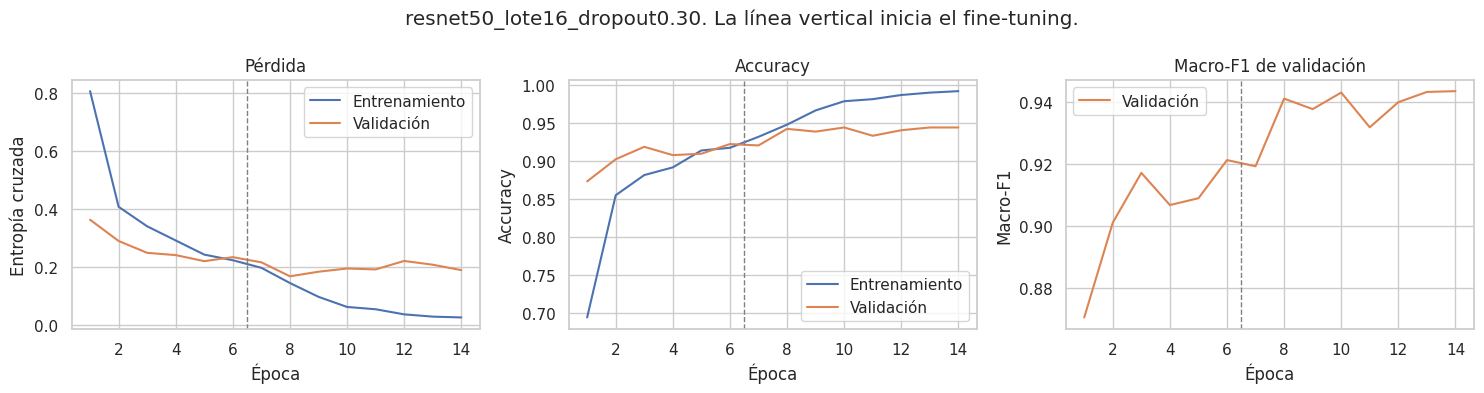

{'id': 'resnet50_lote16_dropout0.30',
 'arquitectura': 'resnet50',
 'tamano_lote': 16,
 'dropout': 0.3,
 'tasa_cabeza': 0.001,
 'tasa_ajuste': 1e-05,
 'epocas_cabeza': 6,
 'mejor_epoca_cabeza': 6,
 'epocas_ajuste': 8,
 'mejor_epoca_ajuste': 8,
 'accuracy_validacion_cabeza': 0.9219600725952813,
 'macro_f1_validacion_cabeza': 0.9211817946001858,
 'accuracy_entrenamiento': 0.9914330244064331,
 'accuracy_validacion': 0.9437386569872959,
 'macro_f1_validacion': 0.9434650478356685,
 'perdida_validacion': 0.1901550441980362,
 'tiempo_segundos': 536.021097391,
 'parametros_entrenables_cabeza': 10245,
 'parametros_entrenables_ajuste': 14963717,
 'capas_entrenables_ajuste': 10,
 'ruta_modelo': 'resultados/checkpoints/resnet50_lote16_dropout0.30.keras'}

In [13]:
if ("resnet50", REF_LOTE, REF_DROPOUT) not in COMBINACIONES:
    raise RuntimeError("La configuración de referencia de ResNet50 no pertenece a la malla.")

ejecutar_experimento("resnet50", REF_LOTE, REF_DROPOUT)


## Sección 8. Malla de hiperparámetros

La malla explícita es el producto de las listas definidas en la configuración:

- Arquitectura: VGG16 y ResNet50.
- Tamaño de lote: 16 y 32 en modo completo. En modo reducido, solo 32.
- Dropout: 0.3 y 0.5.
- Tasa de la cabeza: \(10^{-3}\), fija.
- Tasa de fine-tuning: \(10^{-5}\), fija.
- Épocas máximas y paciencia: las de la celda de configuración. EarlyStopping puede usar menos épocas.

No se modifica el número de filtros internos. Esos anchos forman parte de los pesos de ImageNet; cambiarlos obligaría a inicializar la base al azar y el experimento dejaría de ser transferencia de aprendizaje.

Cada fila registra arquitectura, lote, dropout, tasas, épocas ejecutadas, mejor época de cada fase, accuracy y macro-F1 de validación de la cabeza, accuracy de entrenamiento y de validación tras el fine-tuning, macro-F1 de validación, pérdida de validación, tiempo de reloj y parámetros entrenables. El macro-F1 de la fase 2 es el criterio de selección. La accuracy acompaña la lectura y no decide el modelo.

El ciclo omite los identificadores ya entrenados en VGG16 y ResNet50. Al terminar cada experimento se actualiza `resultados/resumen_experimentos.csv`.


Malla prevista: 8 combinaciones. Ya registradas: 2.
Ya ejecutado, se conserva: vgg16_lote16_dropout0.30

Experimento vgg16_lote16_dropout0.50
Fase 1. Base convolucional congelada.
Capas de la base con pesos entrenables: 0
Esta base no tiene capas BatchNormalization.


Model: "clasificador_vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ promedio_global                 │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ abandono (Dropout)              │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clase (Dense)                   │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,717,253 (56.14 MB)

 Trainable params: 2,565 (10.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 38s 216ms/step - accuracy: 0.3991 - loss: 3.8644 - val_accuracy: 0.6624 - val_loss: 1.3011 - val_macro_f1: 0.6485
Epoch 2/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 35s 191ms/step - accuracy: 0.6063 - loss: 1.8447 - val_accuracy: 0.8058 - val_loss: 0.7561 - val_macro_f1: 0.8039
Epoch 3/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 31s 193ms/step - accuracy: 0.6951 - loss: 1.1883 - val_accuracy: 0.8294 - val_loss: 0.6548 - val_macro_f1: 0.8274
Epoch 4/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 31s 189ms/step - accuracy: 0.7165 - loss: 1.0475 - val_accuracy: 0.8512 - val_loss: 0.5979 - val_macro_f1: 0.8496
Epoch 5/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 41s 192ms/step - accuracy: 0.7558 - loss: 0.8644 - val_accuracy: 0.8421 - val_loss: 0.5797 - val_macro_f1: 0.8399
Epoch 6/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 33s 203ms/step - accuracy: 0.7722 - loss: 0.7656 - val_accuracy: 0.8512 - val_loss: 0.5309 - val_macro_f1: 0.8503
Restoring model weights from the end of the best epoch: 6.
Fase 2. Última etapa de

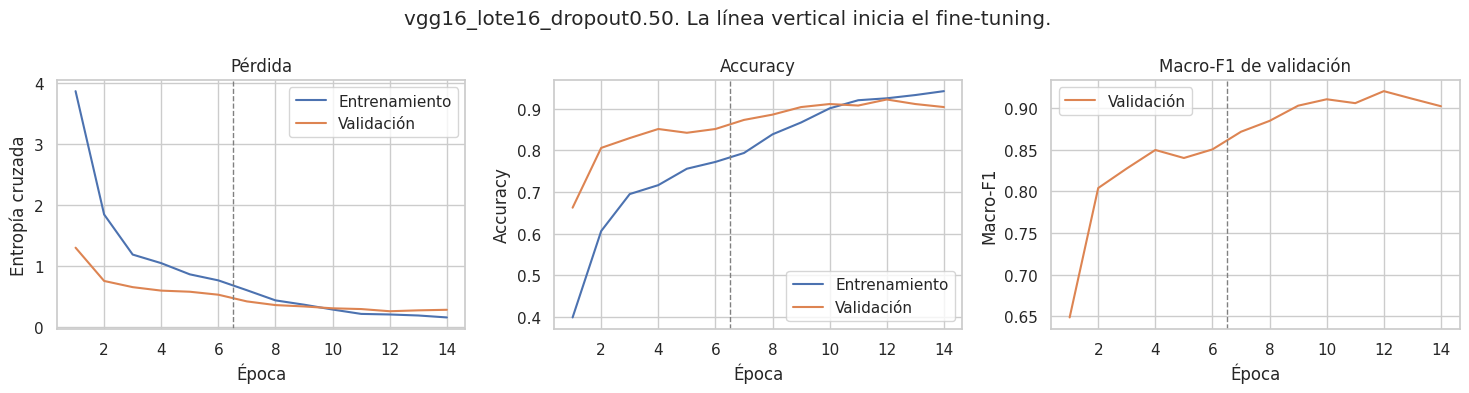


Experimento vgg16_lote32_dropout0.30
Fase 1. Base convolucional congelada.
Capas de la base con pesos entrenables: 0
Esta base no tiene capas BatchNormalization.


Model: "clasificador_vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ promedio_global                 │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ abandono (Dropout)              │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clase (Dense)                   │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,717,253 (56.14 MB)

 Trainable params: 2,565 (10.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 43s 446ms/step - accuracy: 0.3894 - loss: 3.3029 - val_accuracy: 0.6116 - val_loss: 1.4910 - val_macro_f1: 0.5918
Epoch 2/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 34s 420ms/step - accuracy: 0.6153 - loss: 1.6524 - val_accuracy: 0.7405 - val_loss: 0.8869 - val_macro_f1: 0.7358
Epoch 3/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 34s 421ms/step - accuracy: 0.6994 - loss: 1.1194 - val_accuracy: 0.7840 - val_loss: 0.7027 - val_macro_f1: 0.7816
Epoch 4/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 32s 400ms/step - accuracy: 0.7430 - loss: 0.8904 - val_accuracy: 0.8258 - val_loss: 0.6243 - val_macro_f1: 0.8235
Epoch 5/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 32s 398ms/step - accuracy: 0.7706 - loss: 0.7372 - val_accuracy: 0.8512 - val_loss: 0.5764 - val_macro_f1: 0.8501
Epoch 6/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 32s 399ms/step - accuracy: 0.7796 - loss: 0.7031 - val_accuracy: 0.8584 - val_loss: 0.5312 - val_macro_f1: 0.8560
Restoring model weights from the end of the best epoch: 6.
Fase 2. Última etapa descongelada.


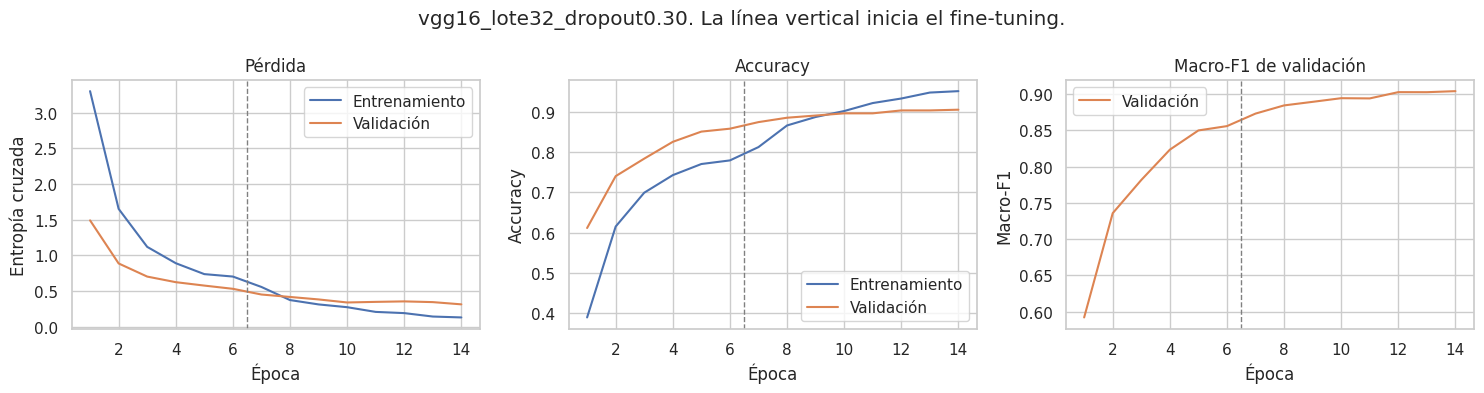


Experimento vgg16_lote32_dropout0.50
Fase 1. Base convolucional congelada.
Capas de la base con pesos entrenables: 0
Esta base no tiene capas BatchNormalization.


Model: "clasificador_vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ promedio_global                 │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ abandono (Dropout)              │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clase (Dense)                   │ (None, 5)              │         2,565 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,717,253 (56.14 MB)

 Trainable params: 2,565 (10.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

Epoch 1/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 38s 433ms/step - accuracy: 0.3559 - loss: 4.3659 - val_accuracy: 0.5935 - val_loss: 1.5707 - val_macro_f1: 0.5795
Epoch 2/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 34s 423ms/step - accuracy: 0.5557 - loss: 2.2897 - val_accuracy: 0.7568 - val_loss: 0.9046 - val_macro_f1: 0.7534
Epoch 3/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 34s 418ms/step - accuracy: 0.6324 - loss: 1.5609 - val_accuracy: 0.7967 - val_loss: 0.7418 - val_macro_f1: 0.7948
Epoch 4/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 35s 435ms/step - accuracy: 0.6869 - loss: 1.1903 - val_accuracy: 0.8312 - val_loss: 0.6517 - val_macro_f1: 0.8292
Epoch 5/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 35s 430ms/step - accuracy: 0.7118 - loss: 1.0162 - val_accuracy: 0.8494 - val_loss: 0.5988 - val_macro_f1: 0.8472
Epoch 6/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 34s 413ms/step - accuracy: 0.7410 - loss: 0.9334 - val_accuracy: 0.8566 - val_loss: 0.5720 - val_macro_f1: 0.8541
Restoring model weights from the end of the best epoch: 6.
Fase 2. Última etapa descongelada.


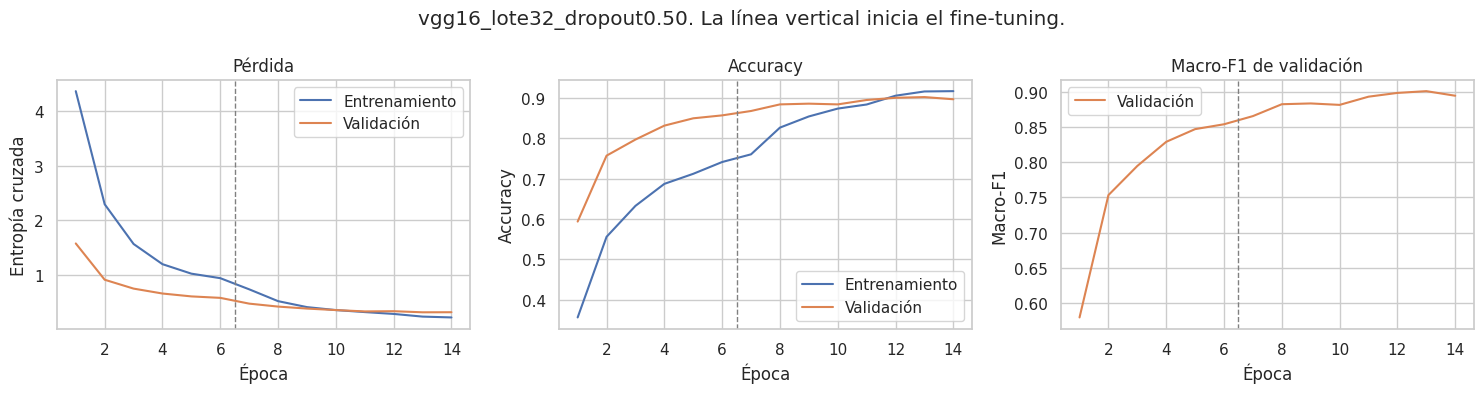

Ya ejecutado, se conserva: resnet50_lote16_dropout0.30

Experimento resnet50_lote16_dropout0.50
Fase 1. Base convolucional congelada.
Capas de la base con pesos entrenables: 0
Capas BatchNormalization: 53. Entrenables: 0.


Model: "clasificador_resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ promedio_global                 │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ abandono (Dropout)              │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clase (Dense)                   │ (None, 5)              │        10,245 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,597,957 (90.02 MB)

 Trainable params: 10,245 (40.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 51s 255ms/step - accuracy: 0.6379 - loss: 0.9904 - val_accuracy: 0.8621 - val_loss: 0.4160 - val_macro_f1: 0.8599
Epoch 2/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 32s 200ms/step - accuracy: 0.8135 - loss: 0.5040 - val_accuracy: 0.8966 - val_loss: 0.3098 - val_macro_f1: 0.8952
Epoch 3/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 31s 193ms/step - accuracy: 0.8567 - loss: 0.4080 - val_accuracy: 0.9111 - val_loss: 0.2716 - val_macro_f1: 0.9099
Epoch 4/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 31s 193ms/step - accuracy: 0.8571 - loss: 0.3756 - val_accuracy: 0.9056 - val_loss: 0.2640 - val_macro_f1: 0.9050
Epoch 5/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 31s 191ms/step - accuracy: 0.8785 - loss: 0.3390 - val_accuracy: 0.9111 - val_loss: 0.2278 - val_macro_f1: 0.9110
Epoch 6/6
161/161 ━━━━━━━━━━━━━━━━━━━━ 30s 188ms/step - accuracy: 0.8820 - loss: 0.3177 - val_accuracy: 0.9111 - val_loss: 0.2604 - val_macro_f1: 0.9093
Restoring model weights from the end of the best epoch: 5.
Fase 2. Última etapa de

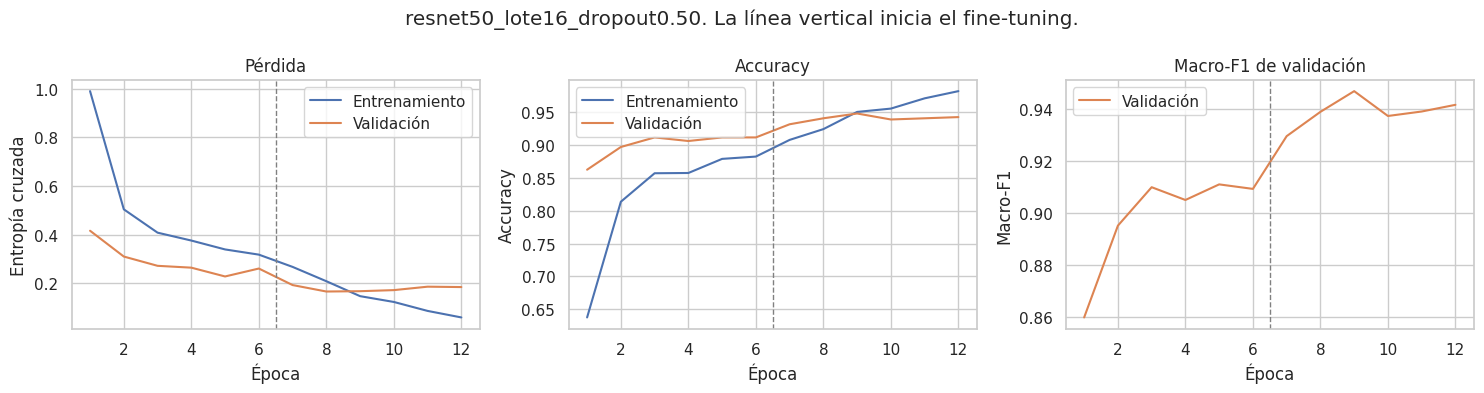


Experimento resnet50_lote32_dropout0.30
Fase 1. Base convolucional congelada.
Capas de la base con pesos entrenables: 0
Capas BatchNormalization: 53. Entrenables: 0.


Model: "clasificador_resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ promedio_global                 │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ abandono (Dropout)              │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clase (Dense)                   │ (None, 5)              │        10,245 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,597,957 (90.02 MB)

 Trainable params: 10,245 (40.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 52s 489ms/step - accuracy: 0.6410 - loss: 0.9392 - val_accuracy: 0.8566 - val_loss: 0.4401 - val_macro_f1: 0.8553
Epoch 2/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 36s 451ms/step - accuracy: 0.8248 - loss: 0.4713 - val_accuracy: 0.8984 - val_loss: 0.3160 - val_macro_f1: 0.8972
Epoch 3/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 31s 381ms/step - accuracy: 0.8711 - loss: 0.3753 - val_accuracy: 0.9111 - val_loss: 0.2961 - val_macro_f1: 0.9101
Epoch 4/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 31s 379ms/step - accuracy: 0.8797 - loss: 0.3174 - val_accuracy: 0.9183 - val_loss: 0.2561 - val_macro_f1: 0.9175
Epoch 5/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 30s 376ms/step - accuracy: 0.8910 - loss: 0.2905 - val_accuracy: 0.9129 - val_loss: 0.2575 - val_macro_f1: 0.9116
Epoch 6/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 31s 384ms/step - accuracy: 0.9073 - loss: 0.2646 - val_accuracy: 0.9238 - val_loss: 0.2595 - val_macro_f1: 0.9229
Restoring model weights from the end of the best epoch: 6.
Fase 2. Última etapa descongelada.


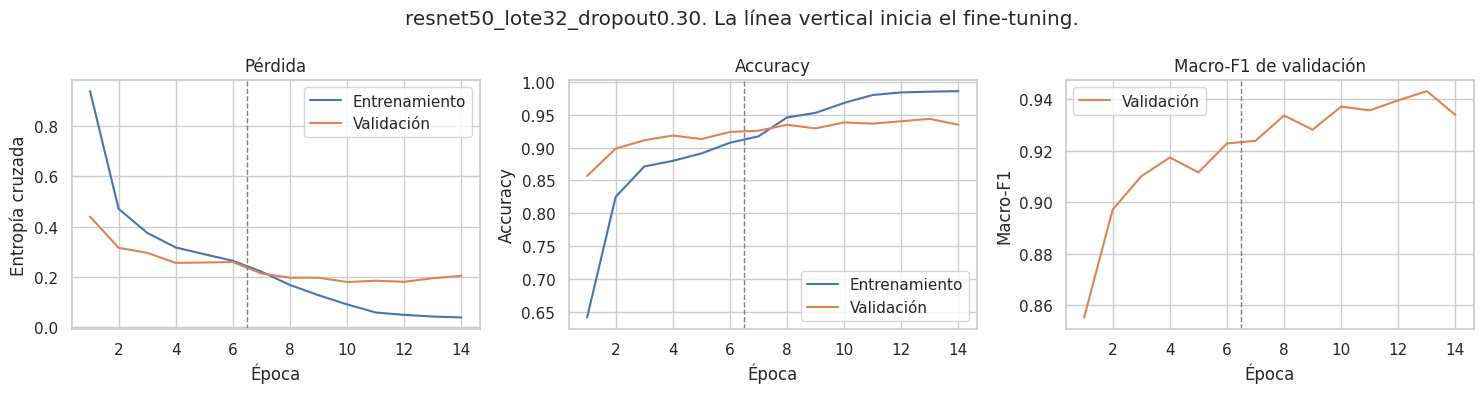


Experimento resnet50_lote32_dropout0.50
Fase 1. Base convolucional congelada.
Capas de la base con pesos entrenables: 0
Capas BatchNormalization: 53. Entrenables: 0.


Model: "clasificador_resnet50"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ promedio_global                 │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ abandono (Dropout)              │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ clase (Dense)                   │ (None, 5)              │        10,245 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,597,957 (90.02 MB)

 Trainable params: 10,245 (40.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 52s 509ms/step - accuracy: 0.5884 - loss: 1.1307 - val_accuracy: 0.8566 - val_loss: 0.4315 - val_macro_f1: 0.8544
Epoch 2/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 32s 389ms/step - accuracy: 0.8022 - loss: 0.5649 - val_accuracy: 0.8911 - val_loss: 0.3266 - val_macro_f1: 0.8904
Epoch 3/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 41s 396ms/step - accuracy: 0.8466 - loss: 0.4502 - val_accuracy: 0.9093 - val_loss: 0.3055 - val_macro_f1: 0.9085
Epoch 4/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 45s 442ms/step - accuracy: 0.8512 - loss: 0.3913 - val_accuracy: 0.9220 - val_loss: 0.2786 - val_macro_f1: 0.9219
Epoch 5/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 30s 376ms/step - accuracy: 0.8758 - loss: 0.3528 - val_accuracy: 0.9093 - val_loss: 0.2721 - val_macro_f1: 0.9085
Epoch 6/6
81/81 ━━━━━━━━━━━━━━━━━━━━ 41s 382ms/step - accuracy: 0.8738 - loss: 0.3422 - val_accuracy: 0.9183 - val_loss: 0.2540 - val_macro_f1: 0.9174
Restoring model weights from the end of the best epoch: 4.
Fase 2. Última etapa descongelada.


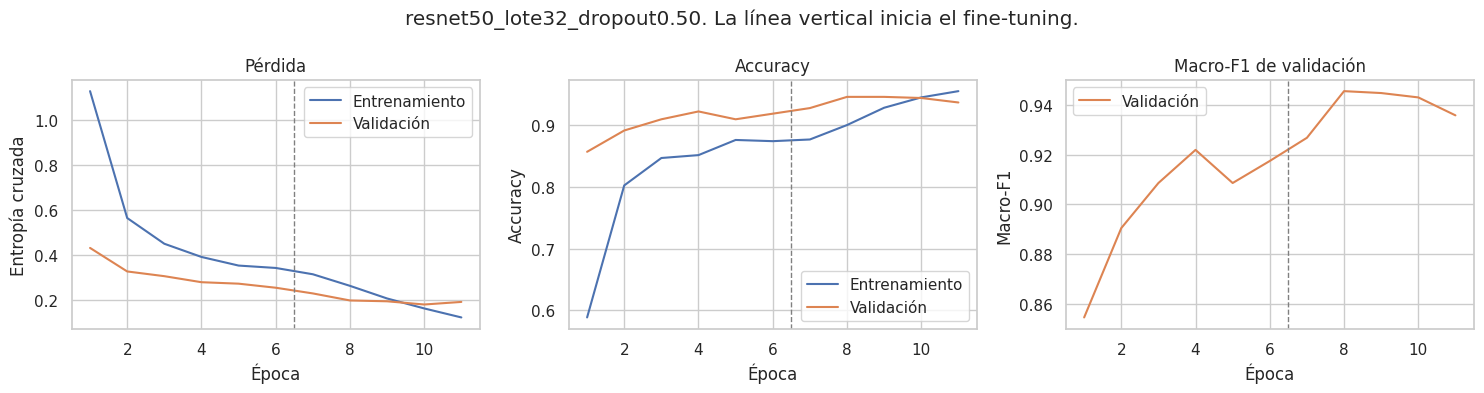

Experimentos disponibles para la comparación: 8 de 8.


In [14]:
print(f"Malla prevista: {len(COMBINACIONES)} combinaciones. Ya registradas: {len(EXPERIMENTOS)}.")
for arquitectura, tamano_lote, dropout in COMBINACIONES:
    id_exp = identificador(arquitectura, tamano_lote, dropout)
    if any(fila["id"] == id_exp for fila in EXPERIMENTOS):
        print("Ya ejecutado, se conserva:", id_exp)
        continue
    ejecutar_experimento(arquitectura, tamano_lote, dropout)

print(f"Experimentos disponibles para la comparación: {len(EXPERIMENTOS)} de {len(COMBINACIONES)}.")
if len(EXPERIMENTOS) < 2:
    raise RuntimeError("La comparación necesita al menos dos configuraciones entrenadas.")
arquitecturas_entrenadas = {fila["arquitectura"] for fila in EXPERIMENTOS}
if arquitecturas_entrenadas != set(ARQUITECTURAS):
    raise RuntimeError(
        "Faltan arquitecturas en el registro. Hay "
        + ", ".join(sorted(arquitecturas_entrenadas))
        + "."
    )


## Sección 9. Comparación y selección

El ordenamiento usa tres claves, todas calculadas en validación o en el reloj de entrenamiento:

1. Mayor macro-F1 de validación después del fine-tuning.
2. Si hay empate, mayor accuracy de validación.
3. Si el empate continúa, menor tiempo de entrenamiento.

El conjunto de prueba no aparece en estas columnas ni en el `sort_values`. No se hace un entrenamiento adicional después de elegir: el candidato ya incluye la fase de fine-tuning y sus pesos restaurados por EarlyStopping. El archivo `mejor_modelo.keras` es una copia de ese checkpoint. `mejor_modelo.json` guarda la configuración necesaria para interpretar la evaluación.

Los promedios por arquitectura, dropout y lote son descriptivos. Con una malla pequeña no se presenta una prueba de significancia.


,id,arquitectura,tamano_lote,dropout,tasa_cabeza,tasa_ajuste,epocas_cabeza,mejor_epoca_cabeza,epocas_ajuste,mejor_epoca_ajuste,macro_f1_validacion_cabeza,macro_f1_validacion,mejora_macro_f1,accuracy_validacion,accuracy_entrenamiento,perdida_validacion,tiempo_segundos,parametros_entrenables_cabeza,parametros_entrenables_ajuste
0,resnet50_lote16_dropout0.50,resnet50,16,0.5,0.001,1e-05,6,5,6,3,0.9110,0.9468,0.0358,0.9474,0.9498,0.1672,462.5389,10245,14963717
1,resnet50_lote32_dropout0.50,resnet50,32,0.5,0.001,1e-05,6,4,5,2,0.9219,0.9455,0.0236,0.9456,0.8999,0.1972,459.0640,10245,14963717
2,resnet50_lote16_dropout0.30,resnet50,16,0.3,0.001,1e-05,6,6,8,8,0.9212,0.9435,0.0223,0.9437,0.9914,0.1902,536.0211,10245,14963717
3,resnet50_lote32_dropout0.30,resnet50,32,0.3,0.001,1e-05,6,6,8,7,0.9229,0.9432,0.0204,0.9437,0.9852,0.1950,543.5399,10245,14963717
4,vgg16_lote16_dropout0.50,vgg16,16,0.5,0.001,1e-05,6,6,8,6,0.8503,0.9202,0.0699,0.9220,0.9248,0.2603,502.8539,2565,7081989
5,vgg16_lote16_dropout0.30,vgg16,16,0.3,0.001,1e-05,6,6,8,7,0.8726,0.9140,0.0414,0.9147,0.9630,0.3022,509.9275,2565,7081989
6,vgg16_lote32_dropout0.30,vgg16,32,0.3,0.001,1e-05,6,6,8,8,0.8560,0.9043,0.0483,0.9056,0.9517,0.3132,517.7495,2565,7081989
7,vgg16_lote32_dropout0.50,vgg16,32,0.5,0.001,1e-05,6,6,8,7,0.8541,0.9012,0.0471,0.9020,0.9159,0.3070,513.5900,2565,7081989


Macro-F1 medio de validación por arquitectura:


,macro_f1_validacion,accuracy_validacion,tiempo_segundos
arquitectura,,,
resnet50,0.9448,0.9451,500.2910
vgg16,0.9099,0.9111,511.0302


Macro-F1 medio de validación por dropout:


,macro_f1_validacion
dropout,
0.3,0.9263
0.5,0.9284


Macro-F1 medio de validación por tamaño de lote:


,macro_f1_validacion
tamano_lote,
16,0.9311
32,0.9236


Modelo seleccionado: resnet50_lote16_dropout0.50 (macro-F1 de validación 0.9468, accuracy de validación 0.9474).


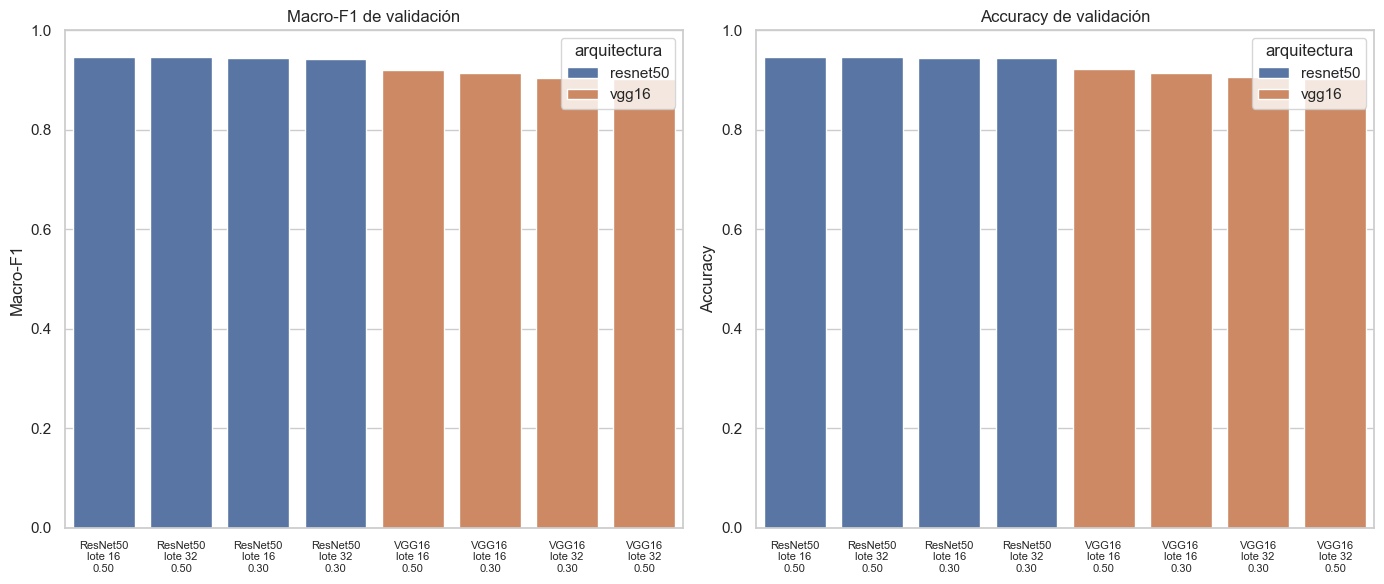

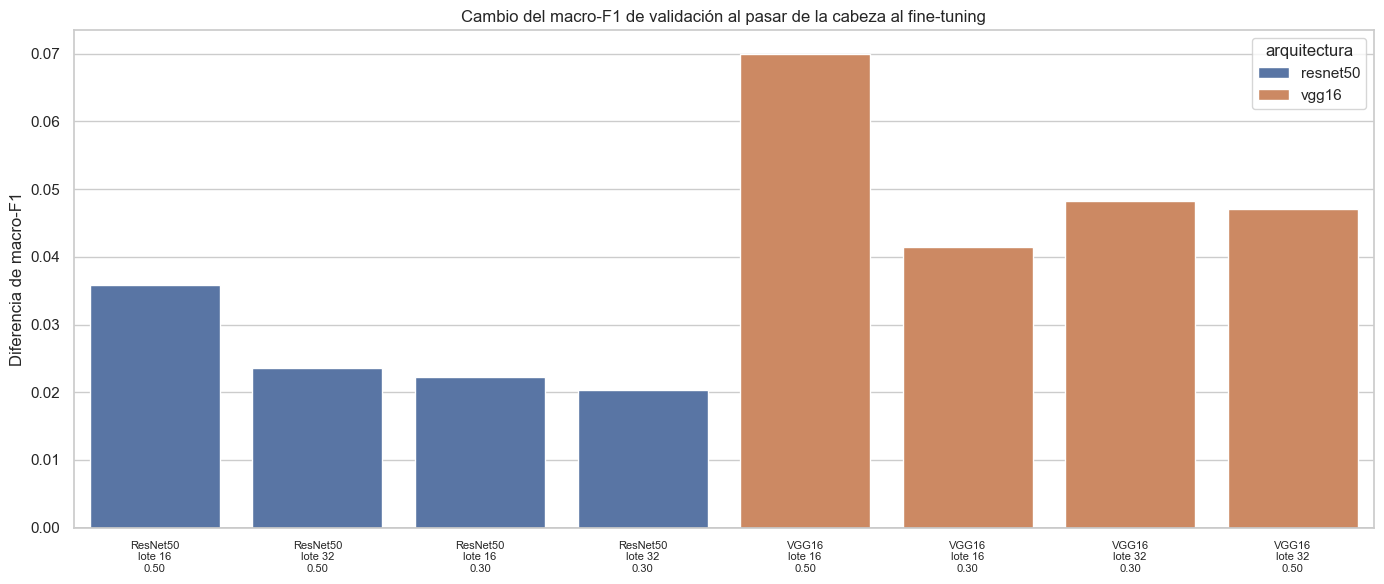

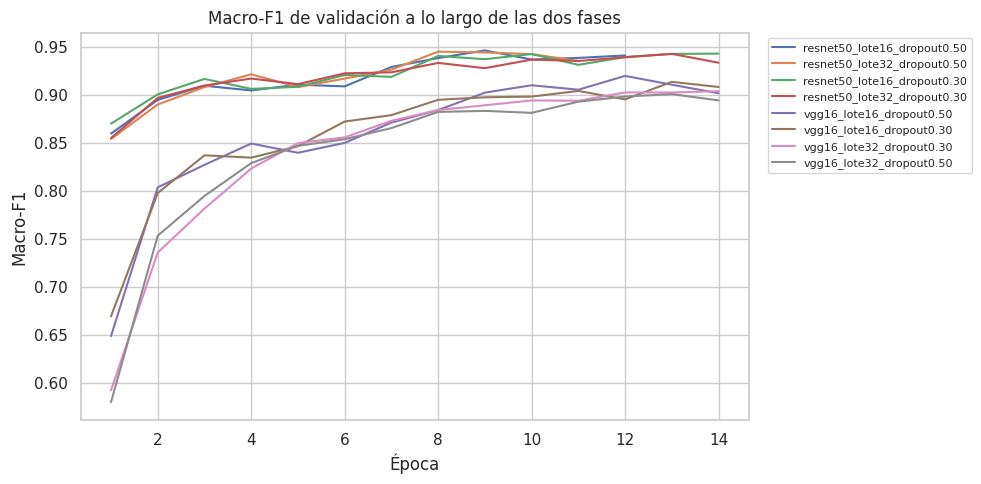

Checkpoint seleccionado copiado en resultados/mejor_modelo.keras


In [15]:
if not EXPERIMENTOS:
    raise RuntimeError("No hay experimentos en memoria. Ejecute las secciones 6, 7 y 8.")

df_experimentos = pd.DataFrame(EXPERIMENTOS)
columnas_seleccion = ["macro_f1_validacion", "accuracy_validacion", "tiempo_segundos"]
for columna in columnas_seleccion:
    if columna not in df_experimentos.columns:
        raise RuntimeError(f"Falta la columna de selección {columna}.")
if any("prueba" in columna for columna in df_experimentos.columns):
    raise RuntimeError("El registro de selección no debe contener métricas de prueba.")

df_experimentos = df_experimentos.sort_values(
    by=columnas_seleccion,
    ascending=[False, False, True],
).reset_index(drop=True)
df_experimentos["mejora_macro_f1"] = (
    df_experimentos["macro_f1_validacion"] - df_experimentos["macro_f1_validacion_cabeza"]
)

columnas_tabla = [
    "id",
    "arquitectura",
    "tamano_lote",
    "dropout",
    "tasa_cabeza",
    "tasa_ajuste",
    "epocas_cabeza",
    "mejor_epoca_cabeza",
    "epocas_ajuste",
    "mejor_epoca_ajuste",
    "macro_f1_validacion_cabeza",
    "macro_f1_validacion",
    "mejora_macro_f1",
    "accuracy_validacion",
    "accuracy_entrenamiento",
    "perdida_validacion",
    "tiempo_segundos",
    "parametros_entrenables_cabeza",
    "parametros_entrenables_ajuste",
]
tabla_visible = df_experimentos[columnas_tabla].copy()
columnas_metricas = [
    "macro_f1_validacion_cabeza",
    "macro_f1_validacion",
    "mejora_macro_f1",
    "accuracy_validacion",
    "accuracy_entrenamiento",
    "perdida_validacion",
    "tiempo_segundos",
]
tabla_visible[columnas_metricas] = tabla_visible[columnas_metricas].round(4)
tabla_visible["tasa_ajuste"] = df_experimentos["tasa_ajuste"].map(lambda valor: f"{float(valor):.0e}")
display(tabla_visible)

print("Macro-F1 medio de validación por arquitectura:")
display(df_experimentos.groupby("arquitectura")[["macro_f1_validacion", "accuracy_validacion", "tiempo_segundos"]].mean().round(4))
print("Macro-F1 medio de validación por dropout:")
display(df_experimentos.groupby("dropout")[["macro_f1_validacion"]].mean().round(4))
print("Macro-F1 medio de validación por tamaño de lote:")
display(df_experimentos.groupby("tamano_lote")[["macro_f1_validacion"]].mean().round(4))

MEJOR_EXPERIMENTO = df_experimentos.iloc[0].to_dict()
print(
    "Modelo seleccionado:",
    MEJOR_EXPERIMENTO["id"],
    f"(macro-F1 de validación {MEJOR_EXPERIMENTO['macro_f1_validacion']:.4f},",
    f"accuracy de validación {MEJOR_EXPERIMENTO['accuracy_validacion']:.4f}).",
)
if len(df_experimentos) < len(COMBINACIONES):
    print(
        f"La selección usa {len(df_experimentos)} de {len(COMBINACIONES)} combinaciones previstas. "
        "Es válida para las corridas terminadas y queda incompleta respecto de la malla configurada."
    )

def etiqueta_experimento(identificador):
    arquitectura, lote, dropout = identificador.split("_")
    nombre = "ResNet50" if arquitectura == "resnet50" else "VGG16"
    return f"{nombre}\n{lote.replace('lote', 'lote ')}\n{dropout.replace('dropout', '')}"


tabla_grafica = df_experimentos.copy()
tabla_grafica["etiqueta"] = tabla_grafica["id"].map(etiqueta_experimento)

fig, ejes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(
    data=tabla_grafica,
    x="etiqueta",
    y="macro_f1_validacion",
    hue="arquitectura",
    dodge=False,
    ax=ejes[0],
)
sns.barplot(
    data=tabla_grafica,
    x="etiqueta",
    y="accuracy_validacion",
    hue="arquitectura",
    dodge=False,
    ax=ejes[1],
)
ejes[0].set_title("Macro-F1 de validación")
ejes[0].set_ylabel("Macro-F1")
ejes[1].set_title("Accuracy de validación")
ejes[1].set_ylabel("Accuracy")
for eje in ejes:
    eje.set_xlabel("")
    eje.tick_params(axis="x", labelsize=8)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "comparacion_validacion.png", bbox_inches="tight")
plt.show()

fig, eje = plt.subplots(figsize=(14, 6))
sns.barplot(
    data=tabla_grafica,
    x="etiqueta",
    y="mejora_macro_f1",
    hue="arquitectura",
    dodge=False,
    ax=eje,
)
eje.axhline(0.0, color="black", linewidth=1)
eje.set_title("Cambio del macro-F1 de validación al pasar de la cabeza al fine-tuning")
eje.set_ylabel("Diferencia de macro-F1")
eje.set_xlabel("")
eje.tick_params(axis="x", labelsize=8)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "efecto_fine_tuning.png", bbox_inches="tight")
plt.show()

fig, eje = plt.subplots(figsize=(10, 5))
for _, fila in df_experimentos.iterrows():
    historial = HISTORIALES[fila["id"]]
    serie = historial["cabeza"]["val_macro_f1"] + historial["ajuste"]["val_macro_f1"]
    eje.plot(np.arange(1, len(serie) + 1), serie, label=fila["id"])
eje.set_title("Macro-F1 de validación a lo largo de las dos fases")
eje.set_xlabel("Época")
eje.set_ylabel("Macro-F1")
eje.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "curvas_macro_f1.png", bbox_inches="tight")
plt.show()

ruta_mejor = RUTA_RESULTADOS / "mejor_modelo.keras"
shutil.copy2(MEJOR_EXPERIMENTO["ruta_modelo"], ruta_mejor)
metadatos_mejor = {
    "id": MEJOR_EXPERIMENTO["id"],
    "arquitectura": MEJOR_EXPERIMENTO["arquitectura"],
    "tamano_lote": int(MEJOR_EXPERIMENTO["tamano_lote"]),
    "dropout": float(MEJOR_EXPERIMENTO["dropout"]),
    "tasa_cabeza": float(MEJOR_EXPERIMENTO["tasa_cabeza"]),
    "tasa_ajuste": float(MEJOR_EXPERIMENTO["tasa_ajuste"]),
    "macro_f1_validacion": float(MEJOR_EXPERIMENTO["macro_f1_validacion"]),
    "accuracy_validacion": float(MEJOR_EXPERIMENTO["accuracy_validacion"]),
    "ruta_modelo": str(ruta_mejor),
}
with open(RUTA_RESULTADOS / "mejor_modelo.json", "w", encoding="utf-8") as archivo:
    json.dump(metadatos_mejor, archivo, ensure_ascii=False, indent=2)
print("Checkpoint seleccionado copiado en", ruta_mejor)


## Sección 10. Evaluación final

Esta sección carga el modelo ya seleccionado y lo aplica al conjunto de prueba. No hay una llamada a `fit`. No se reajustan hiperparámetros con estas métricas.

Se reportan accuracy, precisión macro, recall macro, F1 macro y F1 por clase, el `classification_report`, la matriz de confusión con los nombres oficiales y ejemplos de aciertos y errores con la probabilidad softmax. Las imágenes mostradas son las versiones redimensionadas, antes del preprocesamiento Caffe, para que el color sea reconocible. Las predicciones salen del modelo, que sí recibe la imagen preprocesada.

A partir de la matriz se resumen las confusiones observadas entre clases.


Accuracy de prueba: 0.9365
Precisión macro: 0.9348
Recall macro: 0.9354
F1 macro: 0.9351

Classification report:

              precision    recall  f1-score   support

   dandelion     0.9701    0.9630    0.9665       135
       daisy     0.9574    0.9474    0.9524        95
      tulips     0.9244    0.9167    0.9205       120
  sunflowers     0.9333    0.9333    0.9333       105
       roses     0.8889    0.9167    0.9026        96

    accuracy                         0.9365       551
   macro avg     0.9348    0.9354    0.9351       551
weighted avg     0.9368    0.9365    0.9366       551



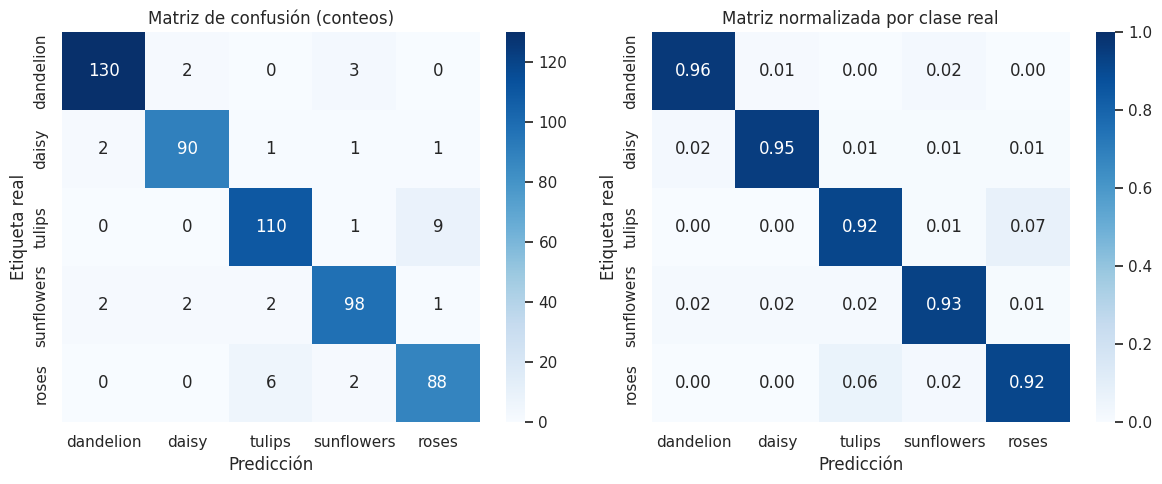

,clase,precision,recall,f1,soporte
0,dandelion,0.9701,0.9630,0.9665,135
1,daisy,0.9574,0.9474,0.9524,95
2,tulips,0.9244,0.9167,0.9205,120
3,sunflowers,0.9333,0.9333,0.9333,105
4,roses,0.8889,0.9167,0.9026,96


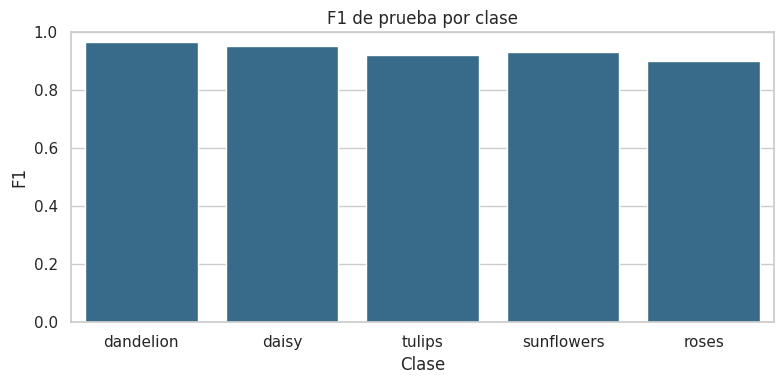

In [16]:
if MEJOR_EXPERIMENTO is None:
    raise RuntimeError("Seleccione primero el modelo en la sección 9.")

ruta_mejor = RUTA_RESULTADOS / "mejor_modelo.keras"
if not ruta_mejor.exists():
    raise RuntimeError("No está el archivo del modelo seleccionado. Ejecute la sección 9.")

keras.backend.clear_session()
gc.collect()
modelo_final = keras.models.load_model(ruta_mejor)
if MEJOR_EXPERIMENTO["arquitectura"] == "vgg16":
    preproceso_final = keras.applications.vgg16.preprocess_input
elif MEJOR_EXPERIMENTO["arquitectura"] == "resnet50":
    preproceso_final = keras.applications.resnet50.preprocess_input
else:
    raise RuntimeError("La arquitectura seleccionada no tiene preprocesamiento definido.")

ds_prueba = crear_pipeline(idx_prueba, 32, preproceso_final, False)
y_true, y_pred, y_prob = predecir_conjunto(modelo_final, ds_prueba)
if not np.array_equal(y_true, etiquetas[np.asarray(idx_prueba)]):
    raise RuntimeError("El orden de la prueba no coincide con los índices reservados.")
if not np.allclose(y_prob.sum(axis=1), 1.0, atol=1e-3):
    raise RuntimeError("Hay filas softmax que no suman aproximadamente 1.")

precision, recall, f1_clases, soporte = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASES)),
    average=None,
    zero_division=0,
)
precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASES)),
    average="macro",
    zero_division=0,
)
accuracy_prueba = float(accuracy_score(y_true, y_pred))
reporte = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASES)),
    target_names=nombres_clases,
    digits=4,
    zero_division=0,
)
matriz = confusion_matrix(y_true, y_pred, labels=list(range(NUM_CLASES)))

print(f"Accuracy de prueba: {accuracy_prueba:.4f}")
print(f"Precisión macro: {precision_macro:.4f}")
print(f"Recall macro: {recall_macro:.4f}")
print(f"F1 macro: {f1_macro:.4f}")
print("\nClassification report:\n")
print(reporte)

RESULTADOS_PRUEBA = {
    "id_modelo": MEJOR_EXPERIMENTO["id"],
    "arquitectura": MEJOR_EXPERIMENTO["arquitectura"],
    "accuracy": accuracy_prueba,
    "precision_macro": float(precision_macro),
    "recall_macro": float(recall_macro),
    "f1_macro": float(f1_macro),
    "f1_por_clase": {nombres_clases[i]: float(f1_clases[i]) for i in range(NUM_CLASES)},
    "precision_por_clase": {nombres_clases[i]: float(precision[i]) for i in range(NUM_CLASES)},
    "recall_por_clase": {nombres_clases[i]: float(recall[i]) for i in range(NUM_CLASES)},
    "soporte_por_clase": {nombres_clases[i]: int(soporte[i]) for i in range(NUM_CLASES)},
    "matriz": matriz.astype(int).tolist(),
    "reporte": reporte,
}
with open(RUTA_RESULTADOS / "evaluacion_prueba.json", "w", encoding="utf-8") as archivo:
    json.dump(RESULTADOS_PRUEBA, archivo, ensure_ascii=False, indent=2)

fig, ejes = plt.subplots(1, 2, figsize=(12, 5))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=nombres_clases,
    yticklabels=nombres_clases,
    ax=ejes[0],
)
matriz_fila = matriz.astype(float)
suma_filas = matriz_fila.sum(axis=1, keepdims=True)
matriz_normalizada = np.divide(matriz_fila, suma_filas, out=np.zeros_like(matriz_fila), where=suma_filas != 0)
sns.heatmap(
    matriz_normalizada,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    xticklabels=nombres_clases,
    yticklabels=nombres_clases,
    ax=ejes[1],
    vmin=0,
    vmax=1,
)
ejes[0].set_title("Matriz de confusión (conteos)")
ejes[1].set_title("Matriz normalizada por clase real")
for eje in ejes:
    eje.set_xlabel("Predicción")
    eje.set_ylabel("Etiqueta real")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "matriz_confusion.png", bbox_inches="tight")
plt.show()

df_por_clase = pd.DataFrame({
    "clase": nombres_clases,
    "precision": precision,
    "recall": recall,
    "f1": f1_clases,
    "soporte": soporte.astype(int),
})
display(df_por_clase.round(4))
fig, eje = plt.subplots(figsize=(8, 4))
sns.barplot(data=df_por_clase, x="clase", y="f1", color="#2a6f97", ax=eje)
eje.set_ylim(0, 1)
eje.set_title("F1 de prueba por clase")
eje.set_xlabel("Clase")
eje.set_ylabel("F1")
fig.tight_layout()
fig.savefig(RUTA_FIGURAS / "f1_por_clase.png", bbox_inches="tight")
plt.show()


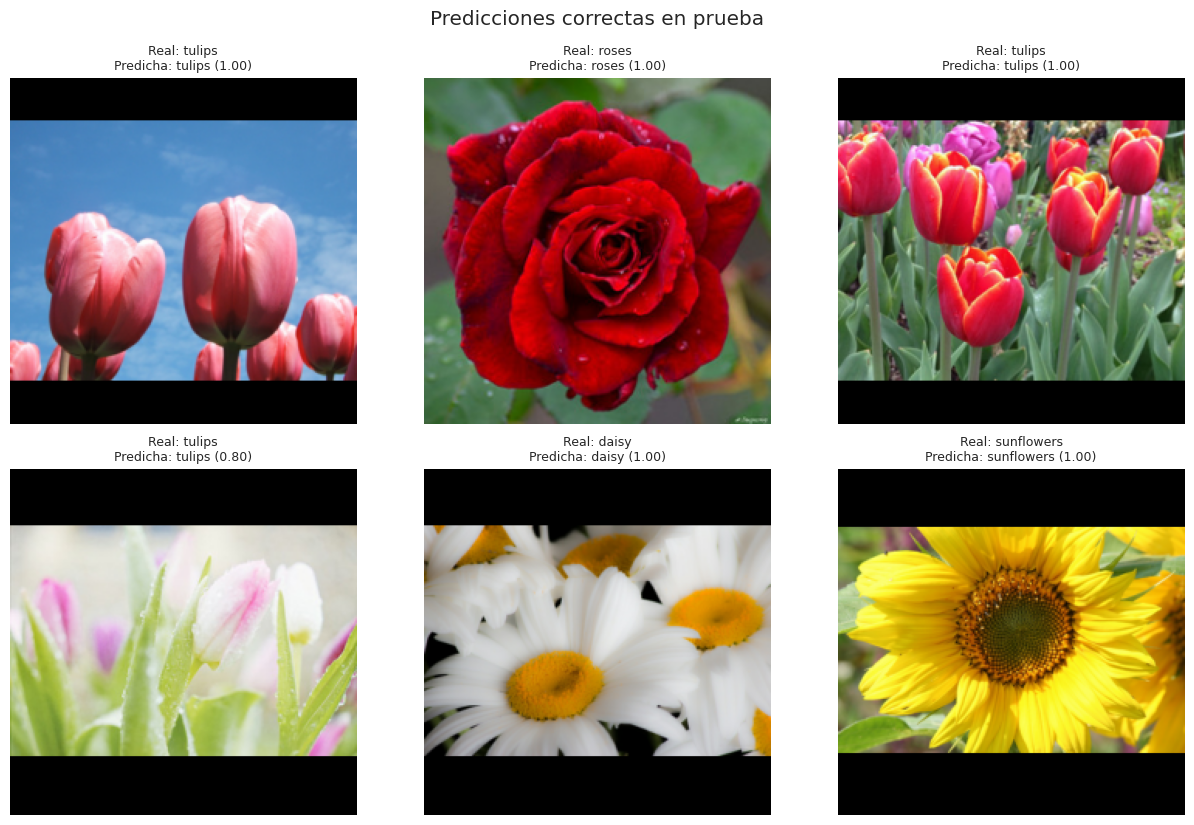

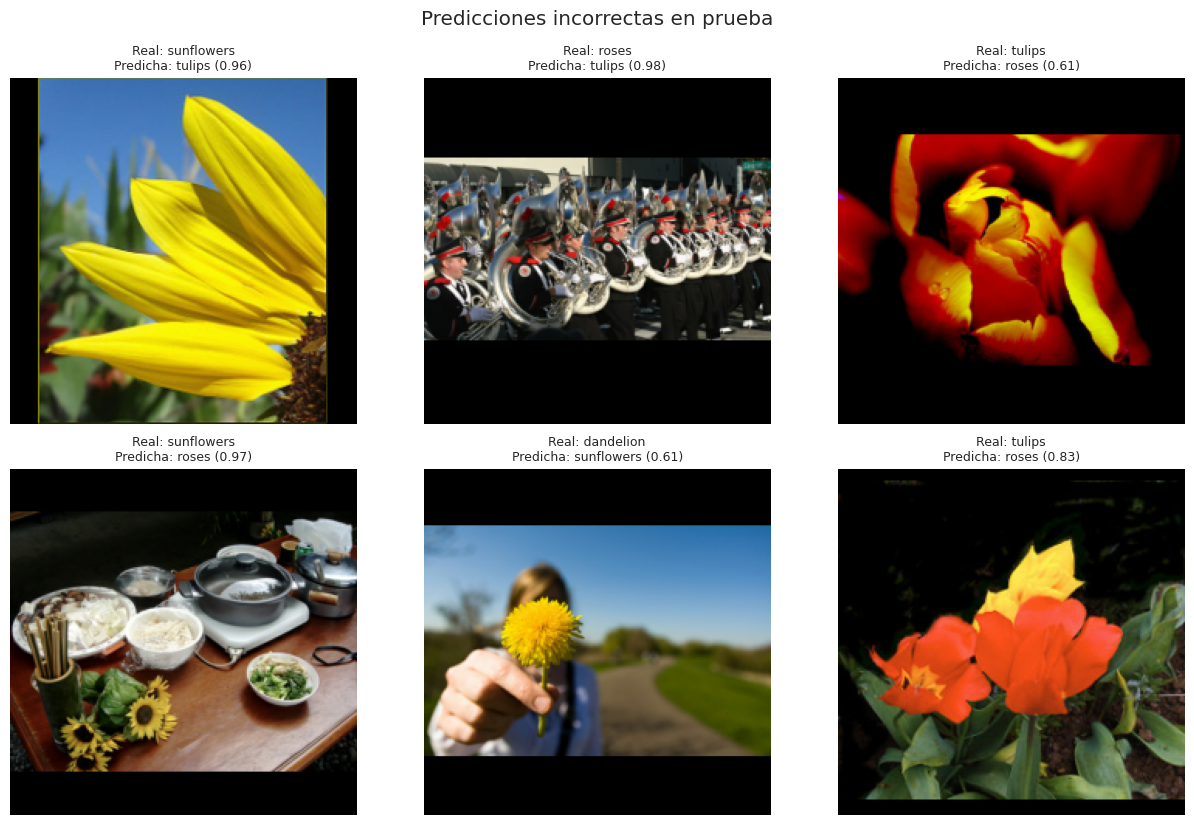

Probabilidades softmax de tres errores y tres aciertos, cuando existen.

Índice de prueba 310. Real: sunflowers. Predicha: tulips.
  dandelion: 0.0177
  daisy: 0.0009
  tulips: 0.9608 <--
  sunflowers: 0.0204
  roses: 0.0002

Índice de prueba 242. Real: roses. Predicha: tulips.
  dandelion: 0.0001
  daisy: 0.0001
  tulips: 0.9823 <--
  sunflowers: 0.0001
  roses: 0.0173

Índice de prueba 300. Real: tulips. Predicha: roses.
  dandelion: 0.0000
  daisy: 0.0000
  tulips: 0.3878
  sunflowers: 0.0004
  roses: 0.6117 <--

Índice de prueba 362. Real: tulips. Predicha: tulips.
  dandelion: 0.0000
  daisy: 0.0000
  tulips: 1.0000 <--
  sunflowers: 0.0000
  roses: 0.0000

Índice de prueba 428. Real: roses. Predicha: roses.
  dandelion: 0.0000
  daisy: 0.0000
  tulips: 0.0000
  sunflowers: 0.0000
  roses: 1.0000 <--

Índice de prueba 240. Real: tulips. Predicha: tulips.
  dandelion: 0.0000
  daisy: 0.0000
  tulips: 1.0000 <--
  sunflowers: 0.0000
  roses: 0.0000
En prueba, resnet50_lote16_dropout

0

In [17]:
def mostrar_muestras(posiciones, titulo):
    posiciones = list(posiciones)
    if len(posiciones) == 0:
        print(f"{titulo}: no hay casos en el conjunto de prueba.")
        return
    columnas = min(3, len(posiciones))
    filas = int(np.ceil(len(posiciones) / columnas))
    fig, ejes = plt.subplots(filas, columnas, figsize=(4.2 * columnas, 4.2 * filas))
    ejes_planos = np.atleast_1d(ejes).ravel()
    for eje, posicion in zip(ejes_planos, posiciones):
        indice_global = int(idx_prueba[posicion])
        eje.imshow(imagenes_224[indice_global])
        real = nombres_clases[int(y_true[posicion])]
        predicha = nombres_clases[int(y_pred[posicion])]
        confianza = float(y_prob[posicion, y_pred[posicion]])
        eje.set_title(f"Real: {real}\nPredicha: {predicha} ({confianza:.2f})", fontsize=9)
        eje.axis("off")
    for eje in ejes_planos[len(posiciones):]:
        eje.axis("off")
    fig.suptitle(titulo)
    fig.tight_layout()
    plt.show()


generador = np.random.default_rng(SEMILLA)
posiciones_acierto = np.flatnonzero(y_true == y_pred)
posiciones_error = np.flatnonzero(y_true != y_pred)
muestra_aciertos = []
muestra_errores = []
if len(posiciones_acierto) > 0:
    muestra_aciertos = generador.choice(
        posiciones_acierto,
        size=min(6, len(posiciones_acierto)),
        replace=False,
    )
if len(posiciones_error) > 0:
    muestra_errores = generador.choice(
        posiciones_error,
        size=min(6, len(posiciones_error)),
        replace=False,
    )

mostrar_muestras(muestra_aciertos, "Predicciones correctas en prueba")
mostrar_muestras(muestra_errores, "Predicciones incorrectas en prueba")

print("Probabilidades softmax de tres errores y tres aciertos, cuando existen.")
posiciones_detalle = list(muestra_errores)[:3] + list(muestra_aciertos)[:3]
if len(posiciones_detalle) == 0:
    print("No hay predicciones para detallar.")
for posicion in posiciones_detalle:
    real = nombres_clases[int(y_true[posicion])]
    predicha = nombres_clases[int(y_pred[posicion])]
    print(f"\nÍndice de prueba {int(posicion)}. Real: {real}. Predicha: {predicha}.")
    for nombre_clase, probabilidad in zip(nombres_clases, y_prob[posicion]):
        marca = " <--" if nombre_clase == predicha else ""
        print(f"  {nombre_clase}: {float(probabilidad):.4f}{marca}")


def interpretar_prueba(resultados, matriz_calculada):
    print(
        f"En prueba, {resultados['id_modelo']} obtuvo accuracy {resultados['accuracy']:.4f}, "
        f"precisión macro {resultados['precision_macro']:.4f}, "
        f"recall macro {resultados['recall_macro']:.4f} y "
        f"F1 macro {resultados['f1_macro']:.4f}."
    )
    for nombre_clase, valor in resultados["f1_por_clase"].items():
        print(
            f"  {nombre_clase}: F1 {valor:.4f}, "
            f"precisión {resultados['precision_por_clase'][nombre_clase]:.4f}, "
            f"recall {resultados['recall_por_clase'][nombre_clase]:.4f}, "
            f"soporte {resultados['soporte_por_clase'][nombre_clase]}."
        )
    pares = []
    matriz_np = np.asarray(matriz_calculada)
    for i in range(len(nombres_clases)):
        for j in range(len(nombres_clases)):
            if i != j and matriz_np[i, j] > 0:
                pares.append((int(matriz_np[i, j]), nombres_clases[i], nombres_clases[j]))
    pares.sort(reverse=True)
    if not pares:
        print("La matriz de prueba no tiene errores fuera de la diagonal.")
    else:
        print("Confusiones observadas, de la etiqueta real hacia la predicción:")
        for cuenta, real, predicha in pares[:5]:
            print(f"  {real} -> {predicha}: {cuenta}")
    diferencia_f1 = resultados["f1_macro"] - float(MEJOR_EXPERIMENTO["macro_f1_validacion"])
    if diferencia_f1 < -0.02:
        lectura_diferencia = (
            "La prueba queda por debajo de la validación. "
            "Conviene leer esa diferencia junto con el tamaño del conjunto de prueba."
        )
    elif diferencia_f1 < 0:
        lectura_diferencia = (
            "La caída es pequeña y no demuestra, por sí sola, un problema grave de generalización."
        )
    else:
        lectura_diferencia = "El F1 de prueba no queda por debajo del de validación."
    print(
        f"El F1 macro de prueba difiere del macro-F1 de validación en {diferencia_f1:+.4f}. "
        f"{lectura_diferencia}"
    )
    brecha = float(MEJOR_EXPERIMENTO["accuracy_entrenamiento"] - MEJOR_EXPERIMENTO["accuracy_validacion"])
    if brecha > 0.08:
        lectura_brecha = (
            "La diferencia es amplia y resulta compatible con sobreajuste, aunque no lo demuestra por sí sola."
        )
    elif max(float(MEJOR_EXPERIMENTO["accuracy_entrenamiento"]), float(MEJOR_EXPERIMENTO["accuracy_validacion"])) < 0.70:
        lectura_brecha = "Entrenamiento y validación quedan por debajo de 0.70, así que el ajuste todavía es limitado."
    else:
        lectura_brecha = (
            "La diferencia es pequeña. Eso no demuestra, por sí solo, que no exista sobreajuste."
        )
    print(
        f"En la mejor época de fine-tuning, la accuracy de entrenamiento fue "
        f"{float(MEJOR_EXPERIMENTO['accuracy_entrenamiento']):.4f} y la de validación "
        f"{float(MEJOR_EXPERIMENTO['accuracy_validacion']):.4f} (diferencia {brecha:+.4f}). "
        f"{lectura_brecha}"
    )


interpretar_prueba(RESULTADOS_PRUEBA, matriz)

keras.backend.clear_session()
gc.collect()


## Sección 11. Conclusiones

Las conclusiones se obtienen de la tabla de experimentos y de la evaluación sobre el conjunto de prueba.

La lectura se apoya en las métricas calculadas:

- El mejor modelo es el de mayor macro-F1 de validación.
- El efecto del fine-tuning es la diferencia entre ese macro-F1 y el de la fase de la cabeza.
- La diferencia entre la accuracy de entrenamiento y la de validación se informa sin tratar una brecha pequeña como prueba de que no hay sobreajuste.
- La diferencia entre el F1 macro de prueba y el de validación se informa por su magnitud. Una caída pequeña no se interpreta, por sí sola, como un fallo grave de generalización.
- Los promedios de dropout y de lote describen la malla ejecutada. No constituyen una prueba de que un valor sea universalmente mejor.

También quedan limitaciones que no dependen de una métrica concreta: cinco clases, fotografías centradas en la flor, distancia entre ImageNet y este dominio, y la imposibilidad de tratar el resultado como un identificador botánico general.


In [18]:
def redactar_conclusiones(tabla, resultados_prueba):
    if resultados_prueba is None:
        raise RuntimeError(
            "No hay evaluación de prueba. Ejecute la sección 10 antes de cerrar las conclusiones. "
            "No se redactan métricas de prueba sin esa ejecución."
        )
    mejor = tabla.iloc[0]
    lineas = []
    lineas.append(
        f"Se compararon {len(tabla)} configuraciones entrenadas de las {len(COMBINACIONES)} previstas "
        f"en el modo {MODO_EXPERIMENTO}. La seleccionada por macro-F1 de validación fue {mejor['id']} "
        f"({mejor['arquitectura']}), con macro-F1 de validación {mejor['macro_f1_validacion']:.4f} y "
        f"accuracy de validación {mejor['accuracy_validacion']:.4f}. "
        f"El desempate previsto, si hiciera falta, usa la accuracy de validación y después el menor tiempo."
    )
    resumen_arquitectura = tabla.groupby("arquitectura")["macro_f1_validacion"].agg(["mean", "max", "count"])
    for arquitectura, fila in resumen_arquitectura.iterrows():
        lineas.append(
            f"{arquitectura} tiene macro-F1 medio de validación {fila['mean']:.4f} y máximo "
            f"{fila['max']:.4f} en {int(fila['count'])} configuraciones."
        )
    delta = tabla["macro_f1_validacion"] - tabla["macro_f1_validacion_cabeza"]
    lineas.append(
        f"El fine-tuning modificó el macro-F1 de validación en un promedio de {delta.mean():+.4f} "
        f"(mínimo {delta.min():+.4f}, máximo {delta.max():+.4f}). "
        f"En el modelo elegido el cambio fue {mejor['mejora_macro_f1']:+.4f}."
    )
    for columna, nombre in (("dropout", "dropout"), ("tamano_lote", "tamaño de lote")):
        grupos = tabla.groupby(columna)["macro_f1_validacion"].mean()
        detalle = ", ".join(f"{indice}: {valor:.4f}" for indice, valor in grupos.items())
        lineas.append(
            f"El macro-F1 medio de validación según {nombre} fue {detalle}. "
            "Es una descripción de la malla ejecutada, no una prueba de que un valor sea universalmente mejor."
        )
    lineas.append(
        f"El tiempo acumulado de los experimentos fue de {tabla['tiempo_segundos'].sum() / 60:.1f} minutos. "
        f"El modelo elegido tardó {mejor['tiempo_segundos'] / 60:.1f} minutos, incluidas las dos fases y "
        "el cálculo de macro-F1 de validación en cada época."
    )
    brecha = float(mejor["accuracy_entrenamiento"] - mejor["accuracy_validacion"])
    if brecha > 0.08:
        lectura_brecha = (
            "La diferencia es amplia y resulta compatible con sobreajuste, aunque no lo demuestra por sí sola."
        )
    elif max(float(mejor["accuracy_entrenamiento"]), float(mejor["accuracy_validacion"])) < 0.70:
        lectura_brecha = "Entrenamiento y validación quedan por debajo de 0.70, así que el ajuste todavía es limitado."
    else:
        lectura_brecha = "La diferencia es pequeña. Eso no demuestra, por sí solo, que no exista sobreajuste."
    lineas.append(
        f"En la mejor época de fine-tuning del modelo elegido, la accuracy de entrenamiento fue "
        f"{mejor['accuracy_entrenamiento']:.4f} y la de validación {mejor['accuracy_validacion']:.4f} "
        f"(diferencia {brecha:+.4f}). {lectura_brecha}"
    )
    lineas.append(
        f"En el conjunto de prueba, no usado para elegir hiperparámetros, el modelo obtuvo "
        f"accuracy {resultados_prueba['accuracy']:.4f}, precisión macro {resultados_prueba['precision_macro']:.4f}, "
        f"recall macro {resultados_prueba['recall_macro']:.4f} y F1 macro {resultados_prueba['f1_macro']:.4f}."
    )
    orden_f1 = sorted(resultados_prueba["f1_por_clase"].items(), key=lambda par: par[1])
    peor_clase, peor_f1 = orden_f1[0]
    mejor_clase, mejor_f1 = orden_f1[-1]
    lineas.append(
        f"La clase con menor F1 de prueba fue {peor_clase} ({peor_f1:.4f}) y la de mayor F1 fue "
        f"{mejor_clase} ({mejor_f1:.4f})."
    )
    diferencia_prueba = resultados_prueba["f1_macro"] - float(mejor["macro_f1_validacion"])
    if diferencia_prueba < -0.02:
        lectura_prueba = (
            "La prueba queda por debajo de la validación. "
            "Conviene leer esa diferencia junto con el tamaño del conjunto de prueba."
        )
    elif diferencia_prueba < 0:
        lectura_prueba = (
            "La caída es pequeña y no demuestra, por sí sola, un problema grave de generalización."
        )
    else:
        lectura_prueba = "El F1 de prueba no queda por debajo del de validación."
    lineas.append(
        f"El F1 macro de prueba menos el macro-F1 de validación es {diferencia_prueba:+.4f}. {lectura_prueba}"
    )
    totales = {"vgg16": 14_717_253, "resnet50": 23_597_957}

    def miles(valor):
        return f"{int(valor):,}".replace(",", ".")

    tiempos = tabla.groupby("arquitectura")["tiempo_segundos"].mean() / 60
    lineas.append(
        "Las limitaciones permanecen aunque la métrica sea alta: el modelo distingue cinco categorías de "
        "tf_flowers, las fotografías están centradas en la flor y los filtros iniciales vienen de ImageNet. "
        "En las redes implementadas, sin la cabeza original de ImageNet y con la cabeza de cinco clases, "
        f"VGG16 tiene {miles(totales['vgg16'])} parámetros totales y ResNet50 tiene {miles(totales['resnet50'])}. "
        f"El tiempo medio fue de {tiempos.loc['vgg16']:.1f} minutos en VGG16 y de "
        f"{tiempos.loc['resnet50']:.1f} minutos en ResNet50. "
        "Esos tiempos son cercanos: el número total de parámetros no explica por sí solo la duración de cada experimento. "
        "Ampliar épocas, descongelar un bloque más o incorporar otro aumento geométrico "
        "son extensiones posibles; habría que volver a separar la prueba y no reutilizar estos números de test "
        "para escoger la variante nueva."
    )
    return "\n\n".join(lineas)


texto_conclusiones = redactar_conclusiones(df_experimentos, RESULTADOS_PRUEBA)
print(texto_conclusiones)
ruta_conclusiones = RUTA_RESULTADOS / "conclusiones.txt"
ruta_conclusiones.write_text(texto_conclusiones, encoding="utf-8")
print("\nConclusiones guardadas en", ruta_conclusiones)


Se compararon 8 configuraciones entrenadas de las 8 previstas en el modo completo. La seleccionada por macro-F1 de validación fue resnet50_lote16_dropout0.50 (resnet50), con macro-F1 de validación 0.9468 y accuracy de validación 0.9474. El desempate previsto, si hiciera falta, usa la accuracy de validación y después el menor tiempo.

resnet50 tiene macro-F1 medio de validación 0.9448 y máximo 0.9468 en 4 configuraciones.

vgg16 tiene macro-F1 medio de validación 0.9099 y máximo 0.9202 en 4 configuraciones.

El fine-tuning modificó el macro-F1 de validación en un promedio de +0.0386 (mínimo +0.0204, máximo +0.0699). En el modelo elegido el cambio fue +0.0358.

El macro-F1 medio de validación según dropout fue 0.3: 0.9263, 0.5: 0.9284. Es una descripción de la malla ejecutada, no una prueba de que un valor sea universalmente mejor.

El macro-F1 medio de validación según tamaño de lote fue 16: 0.9311, 32: 0.9236. Es una descripción de la malla ejecutada, no una prueba de que un valor sea 

## Sección 12. Referencias

Abadi, M., Barham, P., Chen, J., Chen, Z., Davis, A., Dean, J., Devin, M., Ghemawat, S., Irving, G., Isard, M., Kudlur, M., Levenberg, J., Monga, R., Moore, S., Murray, D. G., Steiner, B., Tucker, P., Vasudevan, V., Warden, P., Wicke, M., Yu, Y. y Zheng, X. (2016). TensorFlow: A system for large-scale machine learning. *12th USENIX Symposium on Operating Systems Design and Implementation* (pp. 265-283). https://www.usenix.org/system/files/conference/osdi16/osdi16-abadi.pdf

Chollet, F. y otros. (2015). *Keras*. https://keras.io

Chollet, F. (2020/2023). *Transfer learning & fine-tuning*. Keras. https://keras.io/guides/transfer_learning/

He, K., Zhang, X., Ren, S. y Sun, J. (2016). Deep residual learning for image recognition. *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition* (pp. 770-778). https://arxiv.org/abs/1512.03385

Keras Team. (s. f.). *Keras Applications*. https://keras.io/api/applications/

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M. y Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825-2830.

Russakovsky, O., Deng, J., Su, H., Krause, J., Satheesh, S., Ma, S., Huang, Z., Karpathy, A., Khosla, A., Bernstein, M., Berg, A. C. y Fei-Fei, L. (2015). ImageNet large scale visual recognition challenge. *International Journal of Computer Vision, 115*(3), 211-252. https://doi.org/10.1007/s11263-015-0816-y

Simonyan, K. y Zisserman, A. (2015). Very deep convolutional networks for large-scale image recognition. *International Conference on Learning Representations*. https://arxiv.org/abs/1409.1556

TensorFlow Datasets. (s. f.). *tf_flowers*. https://www.tensorflow.org/datasets/catalog/tf_flowers

TensorFlow Datasets. (s. f.). *tf_flowers dataset builder*. https://github.com/tensorflow/datasets/blob/master/tensorflow_datasets/datasets/tf_flowers/tf_flowers_dataset_builder.py

TensorFlow Team. (2019). *Flowers* [conjunto de datos]. http://download.tensorflow.org/example_images/flower_photos.tgz


## Resumen de la ejecución

La última celda indica cuántos experimentos quedaron registrados, cuál fue el modelo seleccionado y si la evaluación de prueba ya está disponible.


In [19]:
print("Experimentos en memoria:", len(EXPERIMENTOS))
print("Combinaciones previstas:", len(COMBINACIONES))
if MEJOR_EXPERIMENTO is None:
    print("Modelo seleccionado: todavía no.")
else:
    print("Modelo seleccionado:", MEJOR_EXPERIMENTO["id"])
print("Evaluación de prueba disponible:", RESULTADOS_PRUEBA is not None)


Experimentos en memoria: 8
Combinaciones previstas: 8
Modelo seleccionado: resnet50_lote16_dropout0.50
Evaluación de prueba disponible: True
